## Setup
Environment, imports, configuration printout. Nothing here changes any data.

In [25]:
import sys, subprocess
import os

In [26]:
import sys, os
print(sys.executable)      # the python being used right now
print(sys.prefix)          # the environment folder
print(sys.version)
print(os.environ.get("VIRTUAL_ENV"), os.environ.get("CONDA_DEFAULT_ENV"))

/home/aa8624/thesis_2500/venv/bin/python
/home/aa8624/thesis_2500/venv
3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
None None


In [27]:
# List the key package versions in this environment 
print("python:", sys.executable)
print(subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
      .split("\n")[0:0] or "")
out = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if l.lower().split()[0:1] and l.lower().split()[0] in
      ("torch", "torchvision", "torchaudio", "transformers", "huggingface-hub", "open_clip_torch", "open-clip-torch")))

python: /home/aa8624/thesis_2500/venv/bin/python

open_clip_torch           3.3.0
torch                     2.11.0+cu128
torchvision               0.26.0+cu128
transformers              5.13.0


In [28]:
#Pick the GPU (index from nvidia-smi)
# a quiet GPU index from nvidia-smi
os.environ["CUDA_VISIBLE_DEVICES"] = "3"   

In [29]:
# Imports and config printout. 
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))         
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import size_config as sc
import config
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler

%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)


print("PROJECT_ROOT :", config.PROJECT_ROOT)
print("QUICK_RUN    :", config.QUICK_RUN, "  (True = tiny settings, NOT for final results)")
print("family set   :", config.ACTIVE_FAMILY_SET, "| models:", config.MODELS_TO_RUN)
print("seeds        :", config.EXPERIMENT_SEEDS)
try:
    import torch; print("torch        :", torch.__version__, "| CUDA:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (only the logistic-regression models will work)")

PROJECT_ROOT : /data/aa8624/thesis_2500
QUICK_RUN    : False   (True = tiny settings, NOT for final results)
family set   : diffusion_split | models: ['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
seeds        : [42, 43, 44]
torch        : 2.11.0+cu128 | CUDA: True


In [30]:
# Number of data-loader workers for the CNN detectors
config.CNN_NUM_WORKERS = 4

**Optional installs (commented out on purpose).** These two lines change the Python environment, so they are not run
automatically. Uncomment and run them once if `import open_clip` or the Hugging Face hub version fails in Stage 5, then restart the kernel.

In [9]:
# One-off environment fixes. Execute only once.
!{sys.executable} -m pip uninstall -y huggingface-hub
!{sys.executable} -m pip install "huggingface-hub>=1.5,<2.0"
%pip install open_clip_torch

Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)


Note: you may need to restart the kernel to use updated packages.


## Size Ladder Data Setup and Frequency Study

#### Generation

In [15]:
import numpy as np
from PIL import Image
import pandas as pd
import importlib, config, size_config

In [16]:
# Setup and Masks
importlib.reload(config); 
importlib.reload(size_config)
from stage1_generation import diffusion_size_ladder as dsl, ip_size_ladder_generate as ipl
importlib.reload(dsl); 
importlib.reload(ipl)

assert [size_config.IP_TARGET[l] for l in size_config.IP_LEVELS] == list(size_config.DIFF_LEVELS.values())
MK, ERR = dsl.build_masks()
dsl.check_masks(MK)      # expect nesting ~1.0 and "identical to production: N/N"

500 source images | EXISTING production edits cover median 5.00% of the image (range 5.00-5.00%)

Masks per level (of 500 source images):
         n  target  mean_area  min_area  max_area
level                                            
d0p5   499   0.005      0.005     0.005     0.005
d1     497   0.010      0.010     0.010     0.010
d2     496   0.020      0.020     0.020     0.020
d5     496   0.050      0.050     0.050     0.050
d10    490   0.100      0.100     0.100     0.100
masks that could not reach the target: {'d0p5': 1, 'd1': 3, 'd10': 10, 'd2': 4, 'd5': 4}
realised area / target:
         mean  min    max
level                   
d0p5   1.002  1.0  1.002
d1     1.001  1.0  1.001
d2     1.000  1.0  1.001
d5     1.000  1.0  1.000
d10    1.000  1.0  1.000

nesting between neighbouring levels:
 small large   n  mean_inside  min_inside
 d0p5    d1 497          1.0         1.0
   d1    d2 496          1.0         1.0
   d2    d5 496          1.0         1.0
   d5   d10 490     

,small,large,n,mean_inside,min_inside
0,d0p5,d1,497,1.0,1.0
1,d1,d2,496,1.0,1.0
2,d2,d5,496,1.0,1.0
3,d5,d10,490,1.0,1.0


In [17]:
# IP ladder generation
ipl.generate_ladder()

SRC = {"blob": ("metadata/blob_synthetic_metadata.csv", lambda d: d.mask_pixels),
       "copy": ("reports/copy_move_final_metadata.csv", lambda d: d.mask_pixels),
       "texture": ("reports/texture_transplant_final_metadata.csv", lambda d: d.patch_pixels ** 2)}
rows = []
for lv in size_config.IP_LEVELS:
    for tech, (f, area) in SRC.items():
        p = size_config.IP_LADDER_ROOT / lv / tech / f
        if p.exists():
            d = pd.read_csv(p); a = area(d) / 256 ** 2
            rows.append(dict(level=lv, tech=tech, n=len(d), target=size_config.IP_TARGET[lv],
                             mean_area=a.mean().round(4), min=a.min().round(4), max=a.max().round(4)))
print(pd.DataFrame(rows).to_string(index=False))

FINAL BLOB SYNTHETIC DATASET GENERATION

Total source images: 2500

Split counts:
  train       : 1500 (expected 1500)
  val         : 500 (expected 500)
  test        : 500 (expected 500)

Fixed safe ROI:
  x      = 38
  y      = 32
  width  = 179
  height = 192

----------------------------------------------------------------------
Generating train: 1500 images
----------------------------------------------------------------------
Completed train

----------------------------------------------------------------------
Generating val: 500 images
----------------------------------------------------------------------
Completed val

----------------------------------------------------------------------
Generating test: 500 images
----------------------------------------------------------------------
Completed test

GENERATION SUMMARY

Successfully generated: 2500
Missing source images: 0
Generation errors: 0

Synthetic images by split:
split
test      500
train    1500
val       500

Synt

Progress: 2300/2500 | successful=2300 | errors=0
Progress: 2325/2500 | successful=2325 | errors=0
Progress: 2350/2500 | successful=2350 | errors=0
Progress: 2375/2500 | successful=2375 | errors=0
Progress: 2400/2500 | successful=2400 | errors=0
Progress: 2425/2500 | successful=2425 | errors=0
Progress: 2450/2500 | successful=2450 | errors=0
Progress: 2475/2500 | successful=2475 | errors=0
Progress: 2500/2500 | successful=2500 | errors=0

FINAL COPY-MOVE PRODUCTION — VERIFICATION
Expected images: 2500
Successful: 2500
Errors: 0

Generated images by split:
split
test      500
train    1500
val       500
Name: count, dtype: int64

Generated images by disease status:
disease_status
pathology    1250
normal       1250
Name: count, dtype: int64

Sampled patch fraction range:
min = 0.1011
max = 0.1011

Sampled rotation range:
min = 0.0001
max = 14.9977

Sampled scale range:
min = 1.0000
max = 1.1500

Source/destination separation:
minimum observed = 21.63
minimum required = 21.60

All separat

Progress: 25/2500 | successful=25 | errors=0
Progress: 50/2500 | successful=50 | errors=0
Progress: 75/2500 | successful=75 | errors=0
Progress: 100/2500 | successful=100 | errors=0
Progress: 125/2500 | successful=125 | errors=0
Progress: 150/2500 | successful=150 | errors=0
Progress: 175/2500 | successful=175 | errors=0
Progress: 200/2500 | successful=200 | errors=0
Progress: 225/2500 | successful=225 | errors=0
Progress: 250/2500 | successful=250 | errors=0
Progress: 275/2500 | successful=275 | errors=0
Progress: 300/2500 | successful=300 | errors=0
Progress: 325/2500 | successful=325 | errors=0
Progress: 350/2500 | successful=350 | errors=0
Progress: 375/2500 | successful=375 | errors=0
Progress: 400/2500 | successful=400 | errors=0
Progress: 425/2500 | successful=425 | errors=0
Progress: 450/2500 | successful=450 | errors=0
Progress: 475/2500 | successful=475 | errors=0
Progress: 500/2500 | successful=500 | errors=0
Progress: 525/2500 | successful=525 | errors=0
Progress: 550/2500 

  200/500 completed
  225/500 completed
  250/500 completed
  275/500 completed
  300/500 completed
  325/500 completed
  350/500 completed
  375/500 completed
  400/500 completed
  425/500 completed
  450/500 completed
  475/500 completed
  500/500 completed
Generating Texture Transplant images for test: 500
    1/500 completed
   25/500 completed
   50/500 completed
   75/500 completed
  100/500 completed
  125/500 completed
  150/500 completed
  175/500 completed
  200/500 completed
  225/500 completed
  250/500 completed
  275/500 completed
  300/500 completed
  325/500 completed
  350/500 completed
  375/500 completed
  400/500 completed
  425/500 completed
  450/500 completed
  475/500 completed
  500/500 completed

TEXTURE TRANSPLANT PRODUCTION COMPLETE
Generated successfully: 2500
Errors: 0

Images by split:
split
test      500
train    1500
val       500
Name: count, dtype: int64

Target disease:
target_disease
pathology    1250
normal       1250
Name: count, dtype: int64

Don

Progress: 1250/2500 | successful=1250 | errors=0
Progress: 1275/2500 | successful=1275 | errors=0
Progress: 1300/2500 | successful=1300 | errors=0
Progress: 1325/2500 | successful=1325 | errors=0
Progress: 1350/2500 | successful=1350 | errors=0
Progress: 1375/2500 | successful=1375 | errors=0
Progress: 1400/2500 | successful=1400 | errors=0
Progress: 1425/2500 | successful=1425 | errors=0
Progress: 1450/2500 | successful=1450 | errors=0
Progress: 1475/2500 | successful=1475 | errors=0
Progress: 1500/2500 | successful=1500 | errors=0
Progress: 1525/2500 | successful=1525 | errors=0
Progress: 1550/2500 | successful=1550 | errors=0
Progress: 1575/2500 | successful=1575 | errors=0
Progress: 1600/2500 | successful=1600 | errors=0
Progress: 1625/2500 | successful=1625 | errors=0
Progress: 1650/2500 | successful=1650 | errors=0
Progress: 1675/2500 | successful=1675 | errors=0
Progress: 1700/2500 | successful=1700 | errors=0
Progress: 1725/2500 | successful=1725 | errors=0
Progress: 1750/2500 

Completed train

----------------------------------------------------------------------
Generating val: 500 images
----------------------------------------------------------------------
Completed val

----------------------------------------------------------------------
Generating test: 500 images
----------------------------------------------------------------------
Completed test

GENERATION SUMMARY

Successfully generated: 2500
Missing source images: 0
Generation errors: 0

Synthetic images by split:
split
test      500
train    1500
val       500

Synthetic images by disease:
disease_status
pathology    1250
normal       1250

Synthetic images by split and disease:
disease_status  normal  pathology
split                            
test               250        250
train              750        750
val                250        250

SAMPLED PARAMETER SUMMARY
         opacity  radius_fraction  radius_pixels  x_relative  y_relative      sigma
count  2500.0000        2500.0000      2

   25/1500 completed
   50/1500 completed
   75/1500 completed
  100/1500 completed
  125/1500 completed
  150/1500 completed
  175/1500 completed
  200/1500 completed
  225/1500 completed
  250/1500 completed
  275/1500 completed
  300/1500 completed
  325/1500 completed
  350/1500 completed
  375/1500 completed
  400/1500 completed
  425/1500 completed
  450/1500 completed
  475/1500 completed
  500/1500 completed
  525/1500 completed
  550/1500 completed
  575/1500 completed
  600/1500 completed
  625/1500 completed
  650/1500 completed
  675/1500 completed
  700/1500 completed
  725/1500 completed
  750/1500 completed
  775/1500 completed
  800/1500 completed
  825/1500 completed
  850/1500 completed
  875/1500 completed
  900/1500 completed
  925/1500 completed
  950/1500 completed
  975/1500 completed
  1000/1500 completed
  1025/1500 completed
  1050/1500 completed
  1075/1500 completed
  1100/1500 completed
  1125/1500 completed
  1150/1500 completed
  1175/1500 completed
  120

Progress: 450/2500 | successful=303 | errors=147
Progress: 475/2500 | successful=321 | errors=154
Progress: 500/2500 | successful=339 | errors=161
Progress: 525/2500 | successful=353 | errors=172
Progress: 550/2500 | successful=369 | errors=181
Progress: 575/2500 | successful=385 | errors=190
Progress: 600/2500 | successful=403 | errors=197
Progress: 625/2500 | successful=419 | errors=206
Progress: 650/2500 | successful=433 | errors=217
Progress: 675/2500 | successful=451 | errors=224
Progress: 700/2500 | successful=468 | errors=232
Progress: 725/2500 | successful=486 | errors=239
Progress: 750/2500 | successful=505 | errors=245
Progress: 775/2500 | successful=524 | errors=251
Progress: 800/2500 | successful=545 | errors=255
Progress: 825/2500 | successful=557 | errors=268
Progress: 850/2500 | successful=573 | errors=277
Progress: 875/2500 | successful=589 | errors=286
Progress: 900/2500 | successful=605 | errors=295
Progress: 925/2500 | successful=623 | errors=302
Progress: 950/2500 |

  250/500 completed
  275/500 completed
  300/500 completed
  325/500 completed
  350/500 completed
  375/500 completed
  400/500 completed
  425/500 completed
  450/500 completed
  475/500 completed
  500/500 completed

TEXTURE TRANSPLANT PRODUCTION COMPLETE
Generated successfully: 2500
Errors: 0

Images by split:
split
test      500
train    1500
val       500
Name: count, dtype: int64

Target disease:
target_disease
pathology    1250
normal       1250
Name: count, dtype: int64

Donor disease:
donor_disease
pathology    1252
normal       1248
Name: count, dtype: int64

Direction:
direction
pathology_to_pathology    627
pathology_to_normal       625
normal_to_normal          625
normal_to_pathology       623
Name: count, dtype: int64

Parameter ranges actually generated:
Patch fraction: 0.4525 to 0.4525
Rotation: 0.001 to 14.99
Scale: 1.0001 to 1.15
Feather: [0.185]

Metadata:
/data/aa8624/thesis_2500/data/synthetic/IP_size_ladder/a10/texture/reports/texture_transplant_final_metadata.

In [18]:
# diffusion smoke test
G = dsl._load_production_module()
pipeline, _ = G.load_radedit()
ids = MK[MK.level == "d5"].dicom_id.head(3)
meta = dsl.generate(MK[MK.dicom_id.isin(ids) & (MK.level == "d5")], pipeline=pipeline)

LOADING MICROSOFT RADEDIT
Device: cuda:0
Dtype : torch.float16

[1/5] Loading RadEdit U-Net...
      PASS

[2/5] Loading SDXL VAE...
      PASS

[3/5] Loading BioViL-T tokenizer...
      PASS (model_max_length=128)

[4/5] Loading BioViL-T text encoder...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] CXRBertModel LOAD REPORT from: microsoft/BiomedVLP-BioViL-T
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


      PASS

[5/5] Creating DDIM scheduler...
      PASS

Building base diffusion pipeline...
      Base pipeline ready.

Converting to RadEdit editing pipeline...


There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


      RadEdit pipeline ready.

Tokenizer verification:
  tokenizer.model_max_length = 128
      PASS

RADEDIT PIPELINE LOADED SUCCESSFULLY


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


finished: 3 image pairs written | errors this run: 0 | /data/aa8624/thesis_2500/data/synthetic/Diffusion_size_ladder/ladder_metadata.csv
level
d0p5    NaN
d1      NaN
d2      NaN
d5      3.0
d10     NaN
dtype: float64


In [19]:
# Compare with production images
for r in meta[meta.level == "d5"].head(3).itertuples():
    prod = Path(config.DIFFUSION_IMAGE_ROOT) / r.split / r.direction / f"{r.dicom_id}.png"
    a = np.asarray(Image.open(r.full_path).convert("RGB"), float)
    b = np.asarray(Image.open(prod).convert("RGB"), float)
    print(r.dicom_id, "mean abs diff", a.sub(b).mean() if False else np.abs(a - b).mean().round(3), "max", np.abs(a - b).max())

2a58ac46-3f3a383a-b45af58e-22404cf5-0ae84959 mean abs diff 0.0 max 0.0
0333018d-ecbb4d65-00eeca4d-793990b3-9c41bbd5 mean abs diff 0.0 max 0.0
e2bf1d09-d36ab273-469cf62e-9e93f0b6-f5d934ca mean abs diff 0.0 max 0.0


In [20]:
# Full diffusion ladder
meta = dsl.generate(MK, pipeline=pipeline)

20/2478 done, 4.4 min
40/2478 done, 9.4 min
60/2478 done, 14.3 min
80/2478 done, 19.2 min
100/2478 done, 25.3 min
120/2478 done, 31.4 min
140/2478 done, 36.4 min
160/2478 done, 41.3 min
180/2478 done, 46.3 min
200/2478 done, 51.3 min
220/2478 done, 56.3 min
240/2478 done, 61.1 min
260/2478 done, 66.3 min
280/2478 done, 71.5 min
300/2478 done, 76.5 min
320/2478 done, 81.4 min
340/2478 done, 86.3 min
360/2478 done, 91.2 min
380/2478 done, 96.2 min
400/2478 done, 101.5 min
420/2478 done, 106.7 min
440/2478 done, 111.6 min
460/2478 done, 117.0 min
480/2478 done, 121.9 min
500/2478 done, 126.8 min
520/2478 done, 132.2 min
540/2478 done, 137.1 min
560/2478 done, 142.0 min
580/2478 done, 146.8 min
600/2478 done, 151.8 min
620/2478 done, 156.6 min
640/2478 done, 161.4 min
660/2478 done, 166.3 min
680/2478 done, 171.2 min
700/2478 done, 176.0 min
720/2478 done, 181.0 min
740/2478 done, 186.0 min
760/2478 done, 190.9 min
780/2478 done, 195.8 min
800/2478 done, 200.8 min
820/2478 done, 205.6 min


#### Preprocessing

In [24]:
import importlib
from stage2_dataset import ladder_prepare as lp      
importlib.reload(lp)
ip_man, diff_man = lp.prepare_all()

# 1) validate the prepared ladder images (raises if a HARD check fails)
res = lp.validate_ladder()

  IP ladder: prepared 500/7331
  IP ladder: prepared 1000/7331
  IP ladder: prepared 1500/7331
  IP ladder: prepared 2000/7331
  IP ladder: prepared 2500/7331
  IP ladder: prepared 3000/7331
  IP ladder: prepared 3500/7331
  IP ladder: prepared 4000/7331
  IP ladder: prepared 4500/7331
  IP ladder: prepared 5000/7331
  IP ladder: prepared 5500/7331
  IP ladder: prepared 6000/7331
  IP ladder: prepared 6500/7331
  IP ladder: prepared 7000/7331
IP ladder: 7331 images (0 new) -> /data/aa8624/thesis_2500/data/detection/prepared_ladder
  Diffusion ladder: prepared 500/4956
  Diffusion ladder: prepared 1000/4956
  Diffusion ladder: prepared 1500/4956
  Diffusion ladder: prepared 2000/4956
  Diffusion ladder: prepared 2500/4956
  Diffusion ladder: prepared 3000/4956
  Diffusion ladder: prepared 3500/4956
  Diffusion ladder: prepared 4000/4956
  Diffusion ladder: prepared 4500/4956
Diffusion ladder: 4956 images (0 new) -> /data/aa8624/thesis_2500/data/detection/prepared_diff_ladder

IP ladder 

In [ ]:
res = lp.validate_ladder()

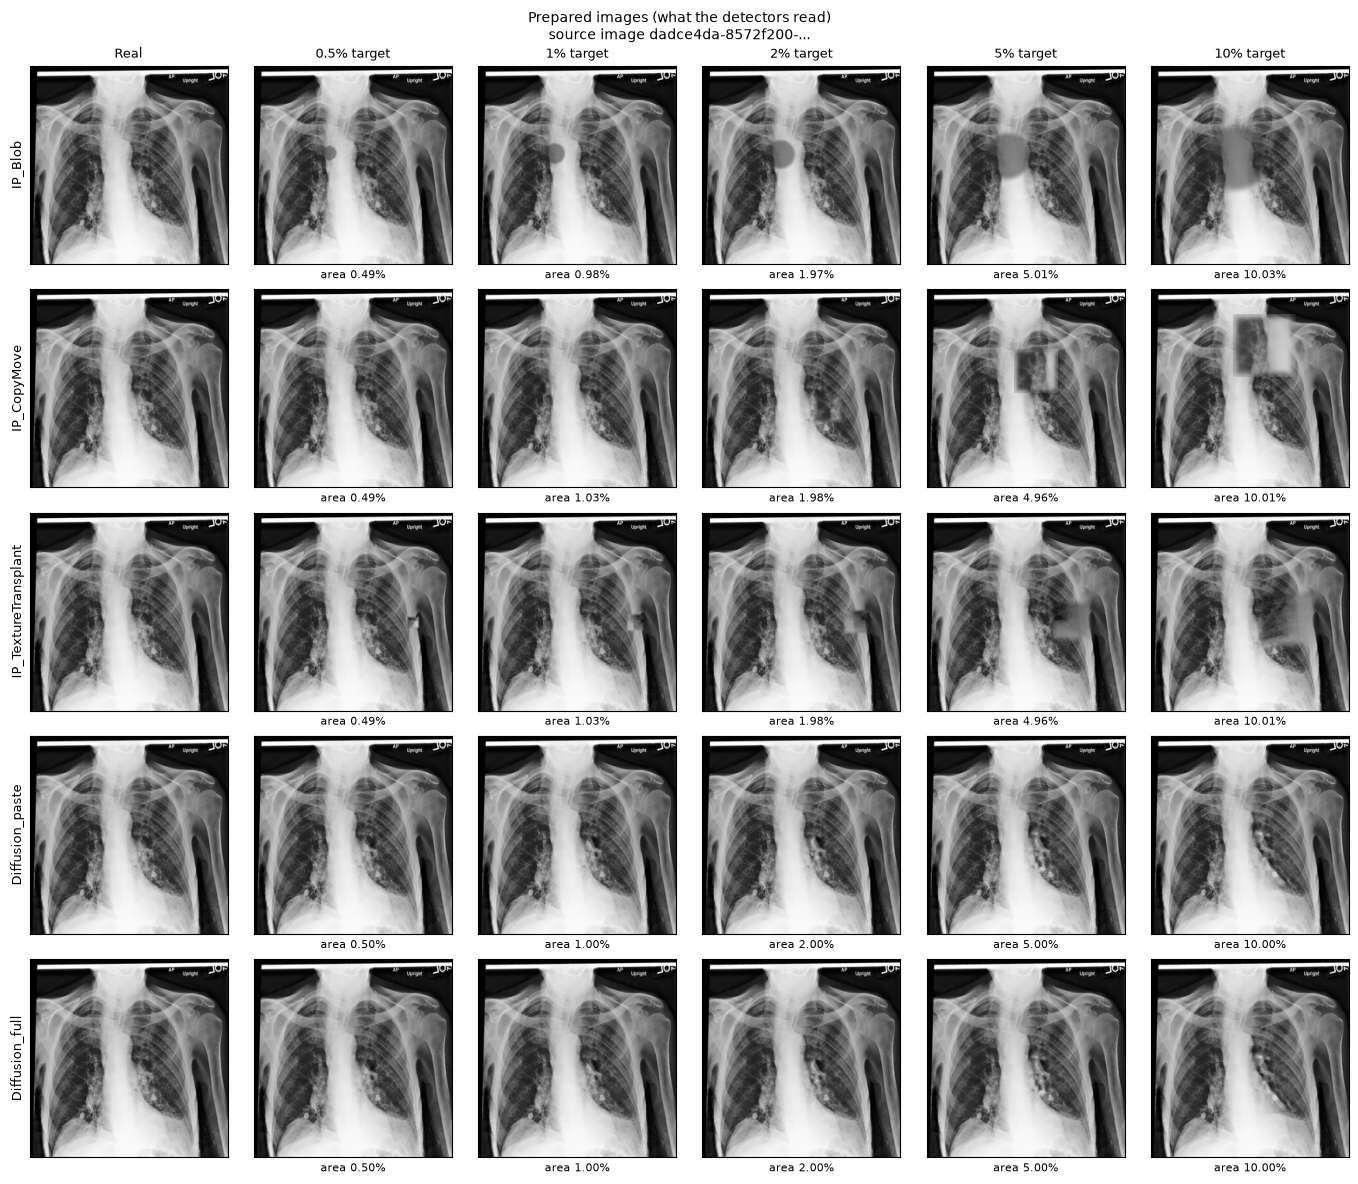

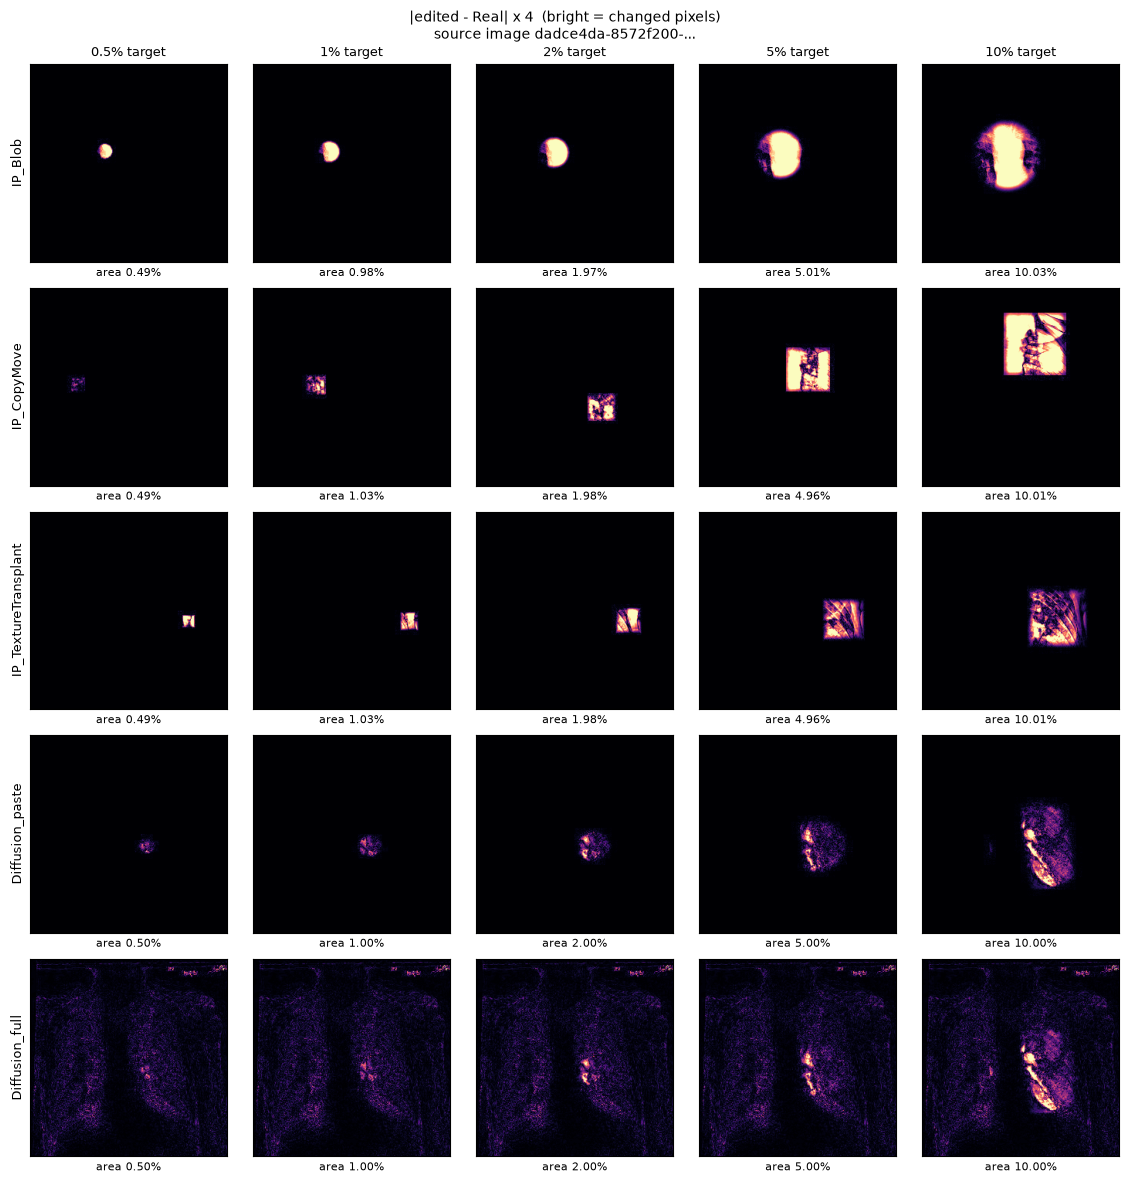

In [25]:
# one source image, every technique (rows) and every size (columns)
dicom = lp.show_example()                 # random image that exists at every group and level
# lp.show_example(dicom_id=dicom)         # re-draw the same image later

#### Frequncy characterisation

In [9]:
import time
from stage3_forensics import ladder_frequency as lf
from stage3_forensics.feature_extractors import extract_feature_dict
from utils.common import load_gray_float01

man = lf.build_manifest()
print(len(man), "images")
t = time.time()
for p in man["prepared_path"].head(20):
    extract_feature_dict(load_gray_float01(p))
print(f"{(time.time() - t) / 20:.3f} s per image  ->  about {(time.time() - t) / 20 * len(man) / 60:.1f} min for one pass")

12787 images
0.021 s per image  ->  about 4.4 min for one pass


Extracting 42 features from 12787 images (n_jobs=1) ...
Saved 12787 rows -> /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/analysis/ladder_frequency/ladder_features.csv
Extracting 6 residual spectral features from 12787 images (n_jobs=1) ...
Saved 12787 rows -> /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/analysis/ladder_frequency/ladder_residual_features.csv

PER GROUP AND LEVEL (n = paired images):
               group level  target_area   area   n  n_features  n_significant  mean_abs_shift_sd          best_feature  best_auroc
      Diffusion_full  d0p5        0.005 0.0050 499          42             36             0.2179        spectral_slope      0.7585
      Diffusion_full    d1        0.010 0.0100 497          42             36             0.2172        spectral_slope      0.7607
      Diffusion_full    d2        0.020 0.0200 496          42             35             0.2157        spectral_slope      0.7682
    

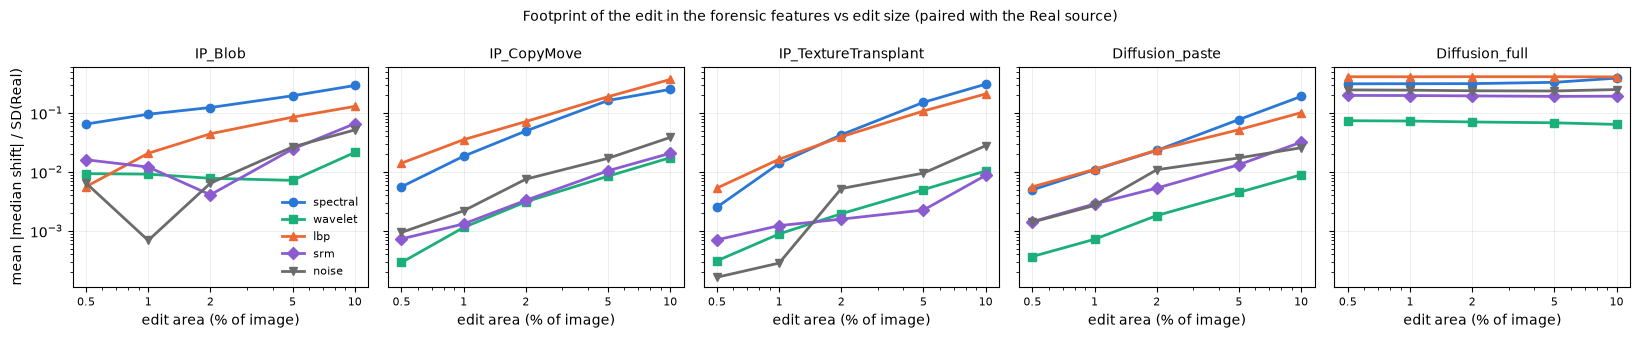

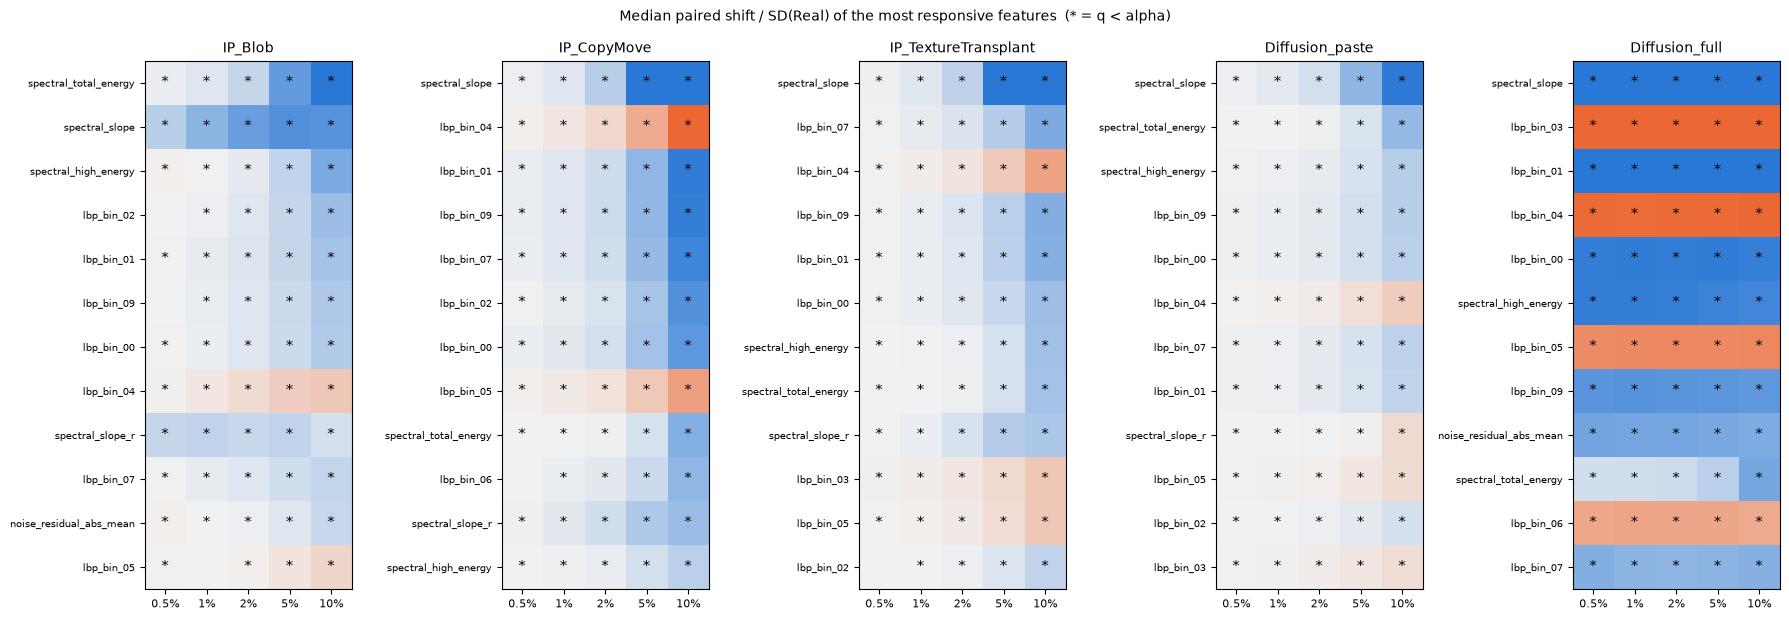

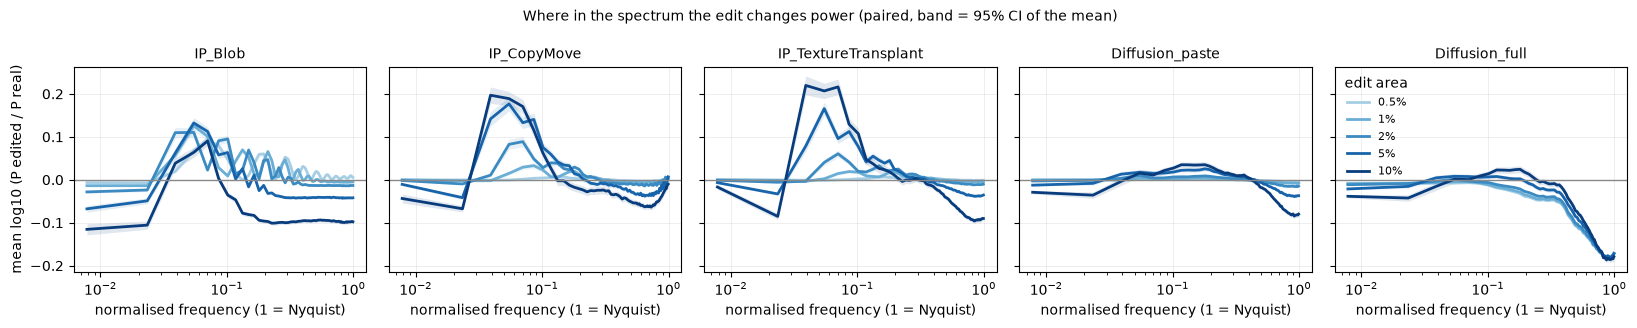

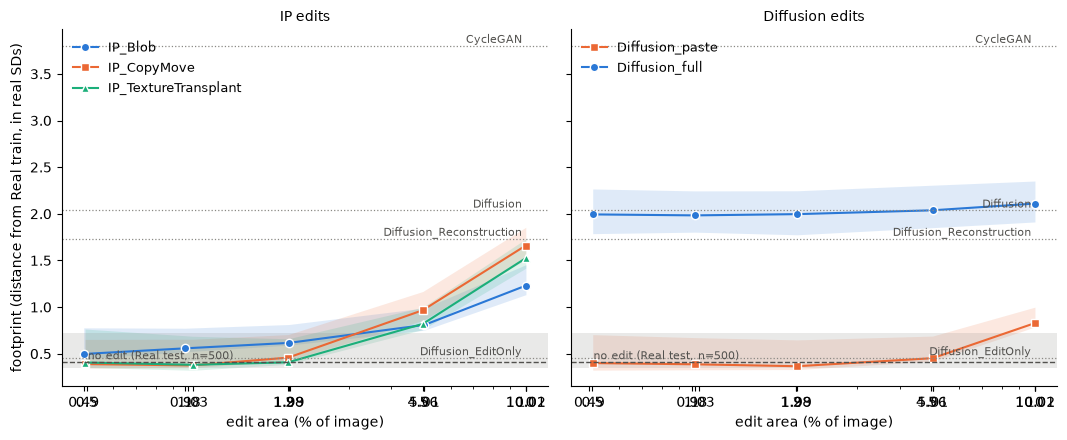

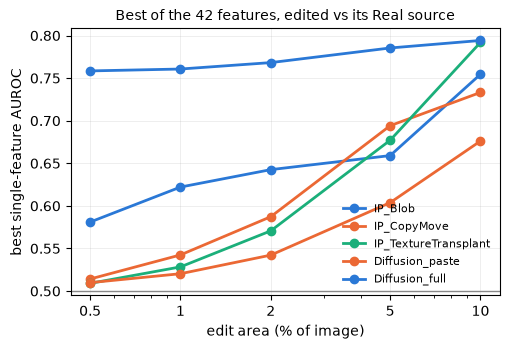


Tables -> /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/analysis/ladder_frequency
Figures -> /data/aa8624/thesis_2500/data/detection/results/figures


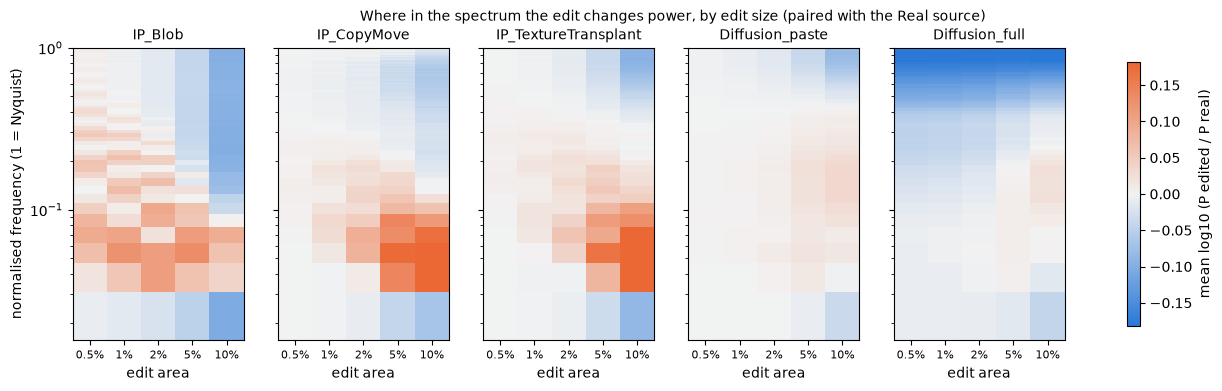

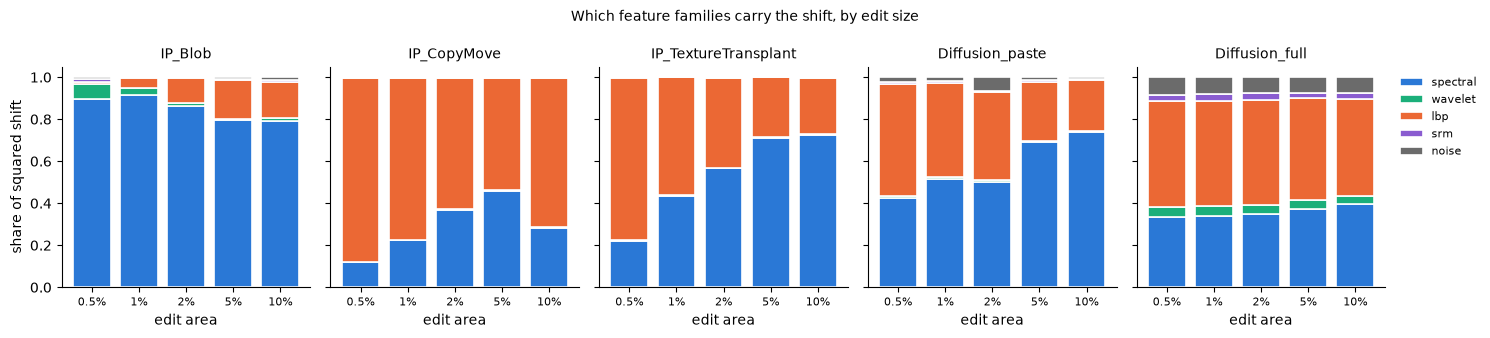

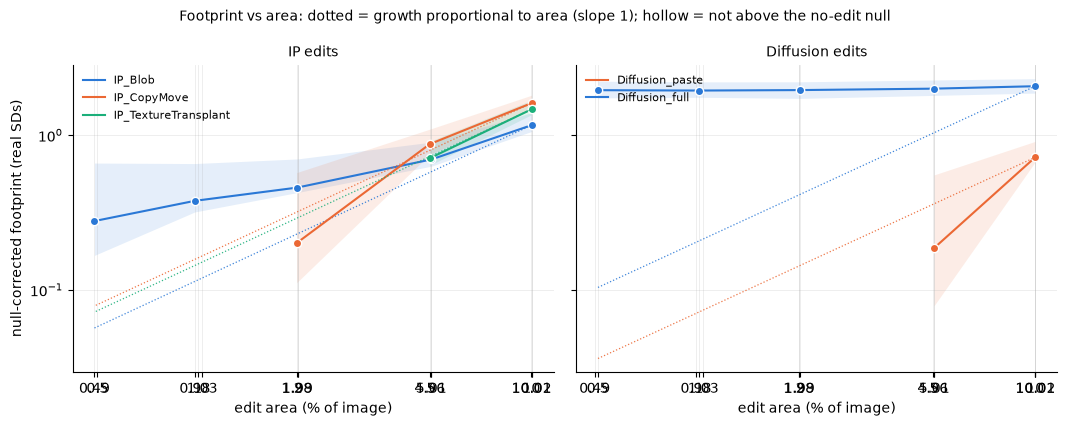

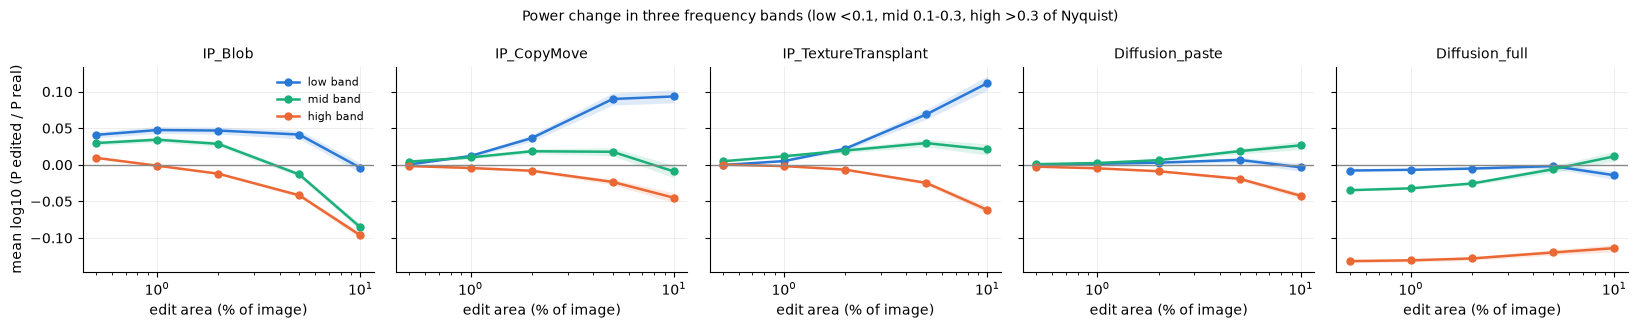

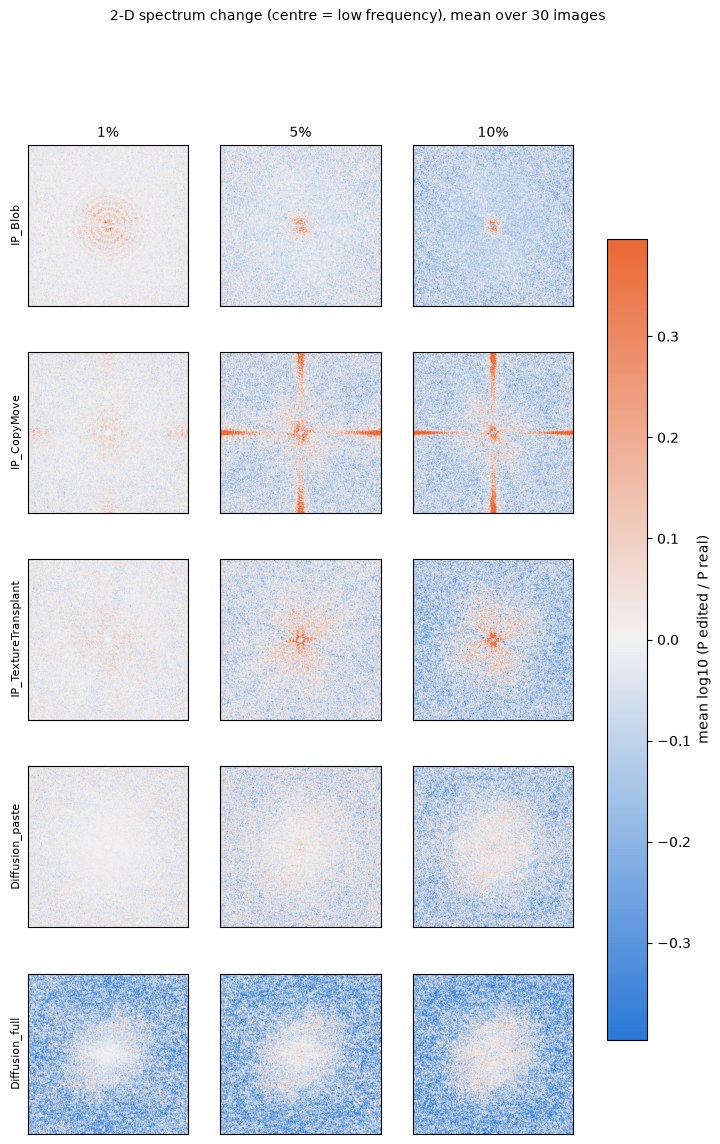

Figures -> /data/aa8624/thesis_2500/data/detection/results/figures


In [10]:
import importlib
from stage3_forensics import footprint, ladder_frequency as lf
out = lf.run_all(n_jobs=1)          # reuses the extracted features
figs = lf.extra_figures(out)   # the five new views; nothing is re-extracted

In [7]:
import stage3_forensics.ladder_frequency as lf

feat = lf.ef.load_feature_table(lf.FEAT_CSV)
rep  = lf.footprint_report(feat)           # or: rep = out["footprint_report"] if `out` is still in memory
null = rep["null"]
print(null)                                 # footprint, lo, hi, n of the Real test images

fp = rep["ladder"].copy()
fp["above_null"]        = fp["lo"] > null["footprint"]      # criterion used in your loglog figure
fp["above_null_strict"] = fp["lo"] > null["hi"]             # stricter: above the null's upper bound
print(fp[["group", "level", "area", "footprint", "lo", "hi", "n",
          "above_null", "above_null_strict"]].round(3).to_string(index=False))

{'footprint': 0.41189899857470613, 'lo': 0.34227659181110476, 'hi': 0.72139840487646, 'n': 500, 'split': 'test'}
               group level  area  footprint    lo    hi   n  above_null  above_null_strict
      Diffusion_full  d0p5 0.005      1.993 1.787 2.266 499        True               True
      Diffusion_full    d1 0.010      1.983 1.803 2.245 497        True               True
      Diffusion_full    d2 0.020      1.996 1.775 2.247 496        True               True
      Diffusion_full    d5 0.050      2.037 1.851 2.307 496        True               True
      Diffusion_full   d10 0.100      2.110 1.912 2.351 490        True               True
     Diffusion_paste  d0p5 0.005      0.399 0.324 0.704 499       False              False
     Diffusion_paste    d1 0.010      0.386 0.328 0.673 497       False              False
     Diffusion_paste    d2 0.020      0.366 0.330 0.648 496       False              False
     Diffusion_paste    d5 0.050      0.452 0.419 0.689 496        T

#### Experimentation

In [11]:
from stage4_experiments import ladder_scoring as ls
import size_config as sc
for label, slug in ls.train_slugs().items():
    print(label, slug, {m: ls.model_seeds(m, slug) for m in sc.MODELS})

IP-trained IP__to__CycleGAN {'spectral_lr': [42], 'handcrafted_lr': [42], 'lbp_lr': [42], 'cnn_densenet': [42, 43, 44], 'supcon': [42, 43, 44], 'npr': [42, 43, 44], 'clip_frozen': [42], 'biomedclip_frozen': [42], 'rad_dino': [42], 'dinov2_frozen': [42]}
Diffusion-trained Diffusion__to__CycleGAN {'spectral_lr': [42], 'handcrafted_lr': [42], 'lbp_lr': [42], 'cnn_densenet': [42, 43, 44], 'supcon': [42, 43, 44], 'npr': [42, 43, 44], 'clip_frozen': [42], 'biomedclip_frozen': [42], 'rad_dino': [42], 'dinov2_frozen': [42]}
EditOnly-trained Diffusion_EditOnly__to__IP {'spectral_lr': [42], 'handcrafted_lr': [42], 'lbp_lr': [42], 'cnn_densenet': [42, 43, 44], 'supcon': [42, 43, 44], 'npr': [42, 43, 44], 'clip_frozen': [42], 'biomedclip_frozen': [42], 'rad_dino': [42], 'dinov2_frozen': [42]}


In [12]:
# Smoke test
import importlib
import size_config as sc
from stage3_forensics import ladder_frequency as lf
from stage4_experiments import ladder_scoring as ls
for m in (sc, lf, ls):
    importlib.reload(m)

R0 = ls.score_ladder(models=["spectral_lr"], slugs={"IP-trained": sc.IP_TRAIN_SLUG}, B=100, save=False)
print(R0[["detector", "group", "level", "area", "n", "auroc", "auroc_lo", "auroc_hi", "win", "boot_bias"]].round(3).to_string(index=False))

500 real test images, 12287 ladder images, 100 bootstrap draws (cluster=subject_id), 484 images per draw
IP-trained / spectral_lr: 1 seed(s) done
   detector                group level  area   n  auroc  auroc_lo  auroc_hi   win  boot_bias
spectral_lr       Diffusion_full  d0p5 0.005 499  0.766     0.742     0.790 1.000      0.000
spectral_lr       Diffusion_full    d1 0.010 497  0.769     0.746     0.793 1.000      0.000
spectral_lr       Diffusion_full    d2 0.020 496  0.779     0.756     0.802 1.000      0.000
spectral_lr       Diffusion_full    d5 0.050 496  0.807     0.785     0.831 1.000      0.001
spectral_lr       Diffusion_full   d10 0.100 490  0.837     0.816     0.860 1.000      0.001
spectral_lr      Diffusion_paste  d0p5 0.005 499  0.509     0.507     0.512 0.938      0.001
spectral_lr      Diffusion_paste    d1 0.010 497  0.522     0.518     0.525 0.958      0.001
spectral_lr      Diffusion_paste    d2 0.020 496  0.547     0.540     0.555 0.964      0.001
spectral_lr      

500 real test images, 12287 ladder images, 1000 bootstrap draws (cluster=subject_id), 484 images per draw
IP-trained / spectral_lr: 1 seed(s) done
IP-trained / handcrafted_lr: 1 seed(s) done
IP-trained / lbp_lr: 1 seed(s) done
IP-trained / cnn_densenet: 3 seed(s) done
IP-trained / supcon: 3 seed(s) done
IP-trained / npr: 3 seed(s) done
    [clip_frozen] embedding 12287 new / changed images ...


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

IP-trained / clip_frozen: 1 seed(s) done
    [biomedclip_frozen] embedding 12287 new / changed images ...
IP-trained / biomedclip_frozen: 1 seed(s) done
    [rad_dino] embedding 12287 new / changed images ...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

IP-trained / rad_dino: 1 seed(s) done
    [dinov2_frozen] embedding 12287 new / changed images ...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

IP-trained / dinov2_frozen: 1 seed(s) done
Diffusion-trained / spectral_lr: 1 seed(s) done
Diffusion-trained / handcrafted_lr: 1 seed(s) done
Diffusion-trained / lbp_lr: 1 seed(s) done
Diffusion-trained / cnn_densenet: 3 seed(s) done
Diffusion-trained / supcon: 3 seed(s) done
Diffusion-trained / npr: 3 seed(s) done
Diffusion-trained / clip_frozen: 1 seed(s) done
Diffusion-trained / biomedclip_frozen: 1 seed(s) done
Diffusion-trained / rad_dino: 1 seed(s) done
Diffusion-trained / dinov2_frozen: 1 seed(s) done
EditOnly-trained / spectral_lr: 1 seed(s) done
EditOnly-trained / handcrafted_lr: 1 seed(s) done
EditOnly-trained / lbp_lr: 1 seed(s) done
EditOnly-trained / cnn_densenet: 3 seed(s) done
EditOnly-trained / supcon: 3 seed(s) done
EditOnly-trained / npr: 3 seed(s) done
EditOnly-trained / clip_frozen: 1 seed(s) done
EditOnly-trained / biomedclip_frozen: 1 seed(s) done
EditOnly-trained / rad_dino: 1 seed(s) done
EditOnly-trained / dinov2_frozen: 1 seed(s) done
Saved 750 rows -> /data/a

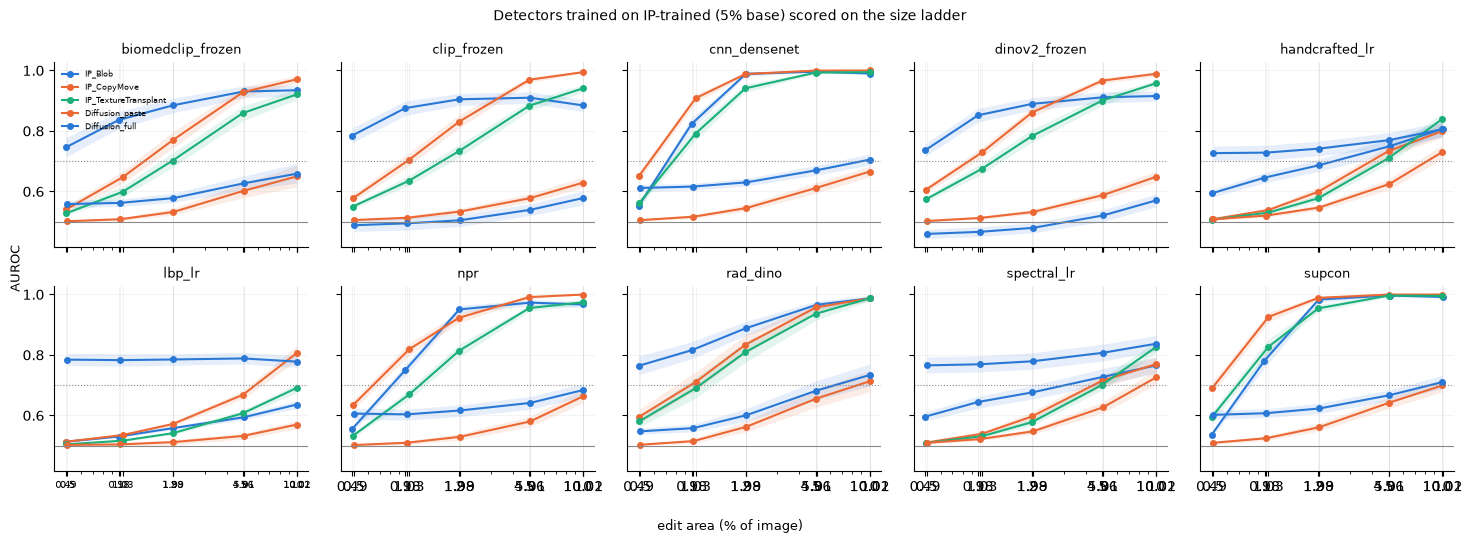

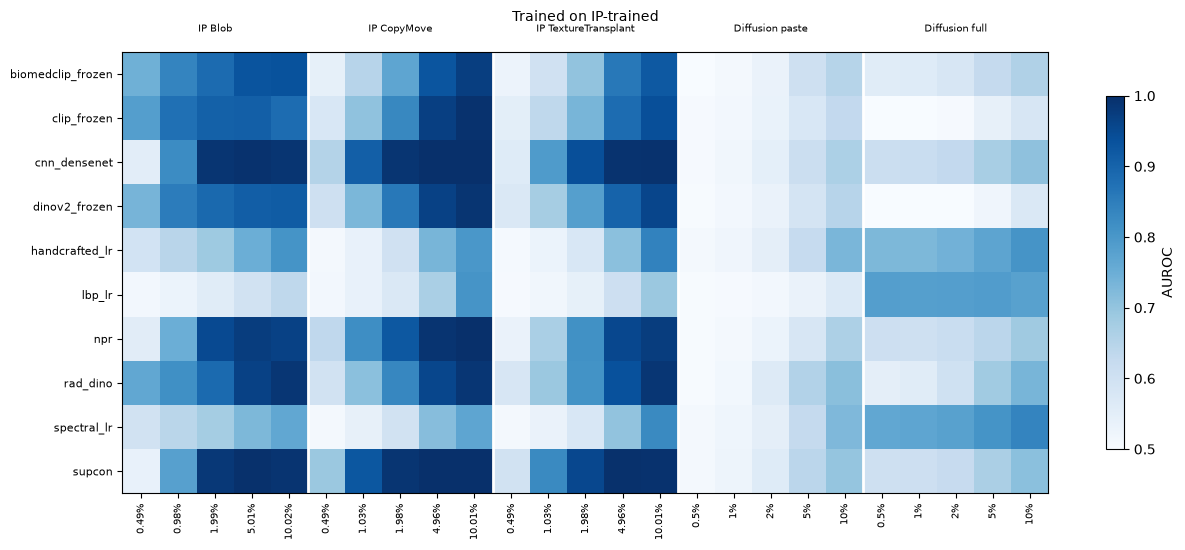

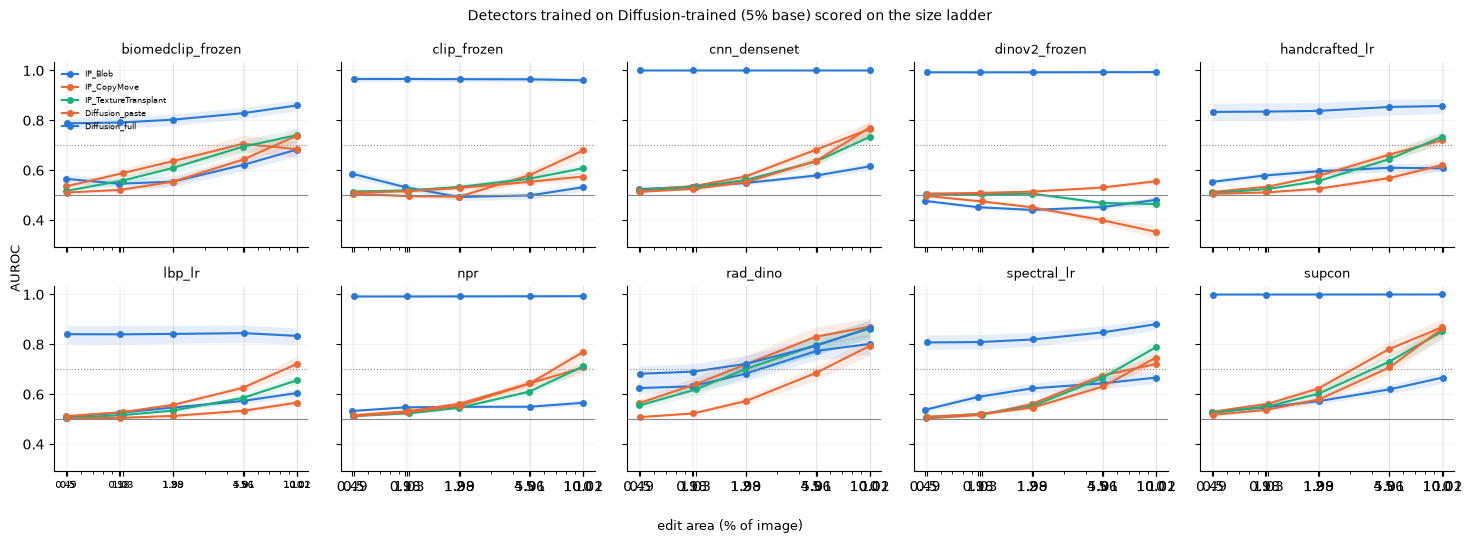

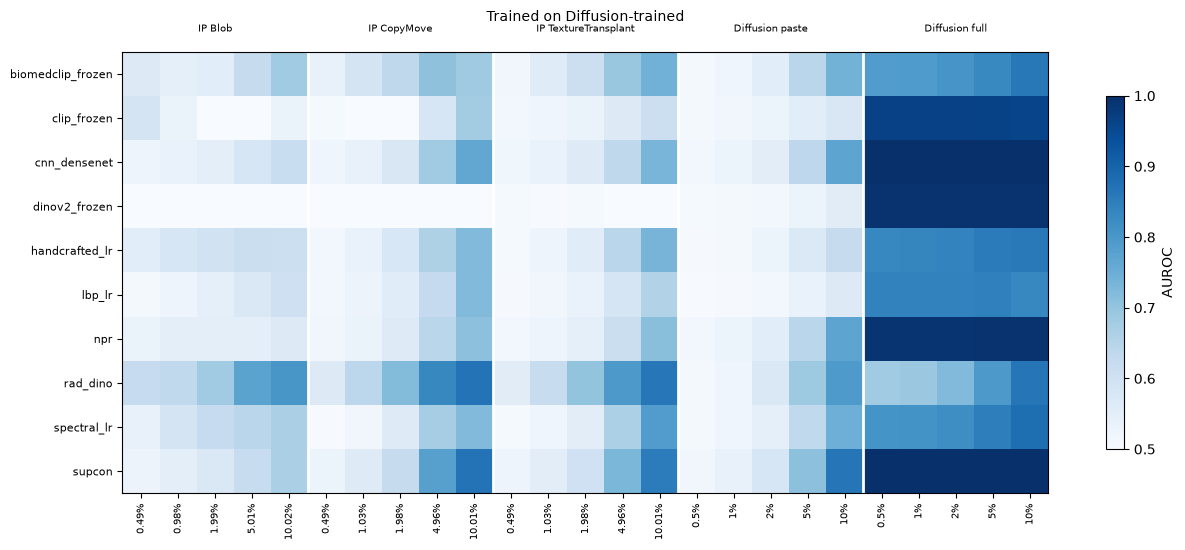

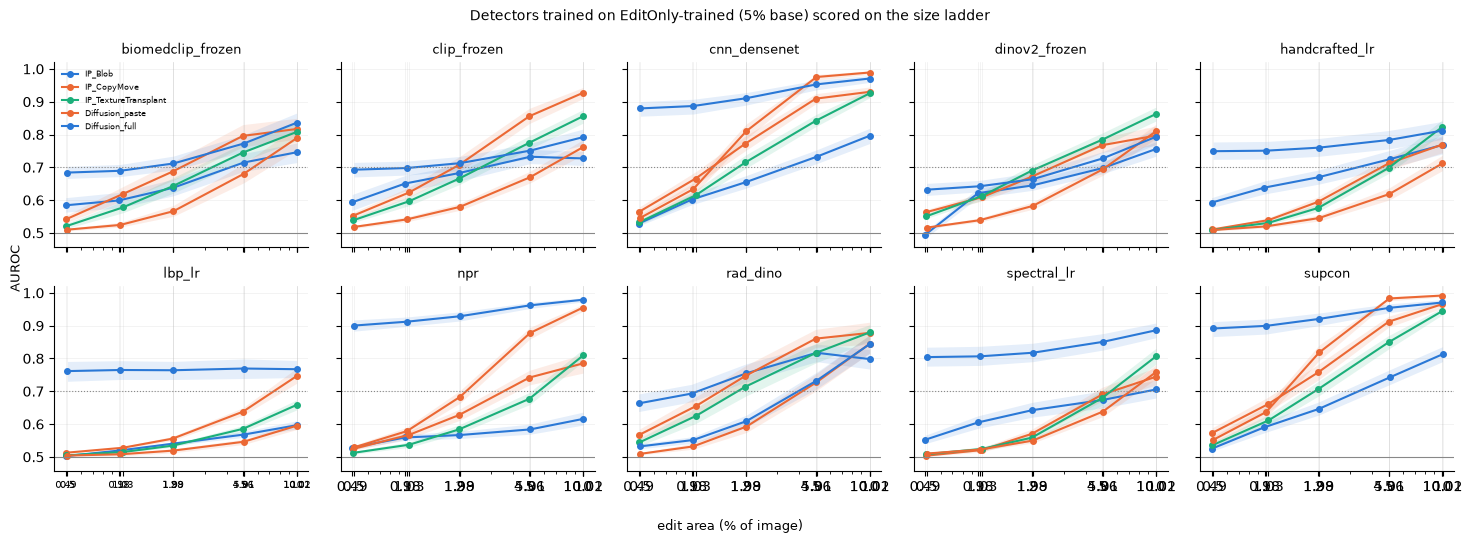

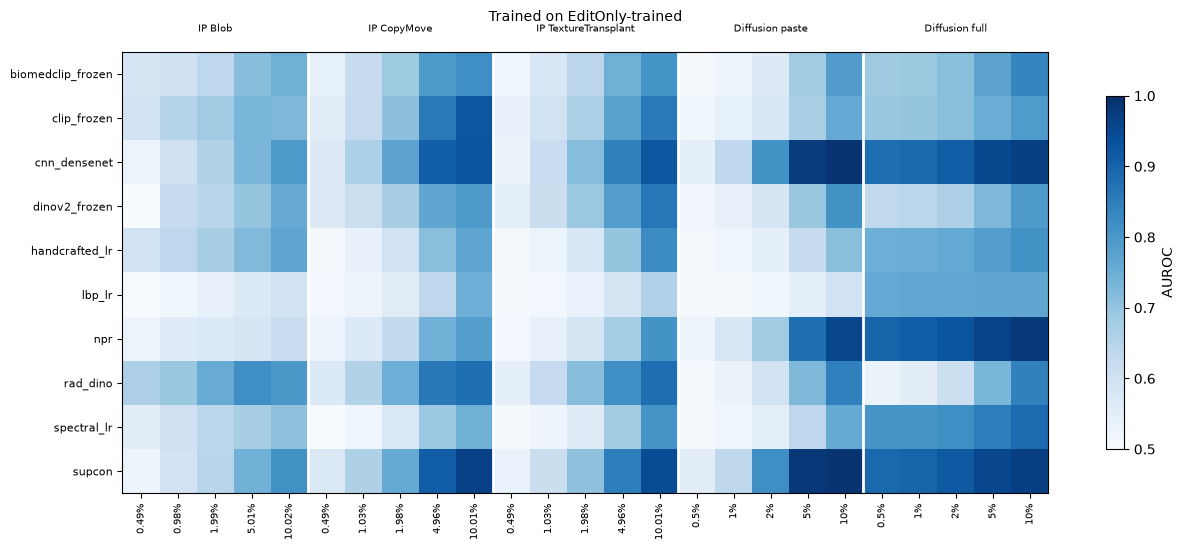

,train,detector,series,ladder_auroc,base_auroc,diff
0,Diffusion-trained,biomedclip_frozen,Diffusion_full,0.829157,0.829157,1.110223e-16
1,Diffusion-trained,clip_frozen,Diffusion_full,0.964528,0.964528,0.000000e+00
2,Diffusion-trained,cnn_densenet,Diffusion_full,0.999921,0.999921,0.000000e+00
3,Diffusion-trained,dinov2_frozen,Diffusion_full,0.993165,0.993165,0.000000e+00
4,Diffusion-trained,handcrafted_lr,Diffusion_full,0.853774,0.853774,0.000000e+00
...,...,...,...,...,...,...
145,IP-trained,lbp_lr,IP_TextureTransplant,0.607316,0.611092,-3.776000e-03
146,IP-trained,npr,IP_TextureTransplant,0.954936,0.964189,-9.253333e-03
147,IP-trained,rad_dino,IP_TextureTransplant,0.936100,0.935948,1.520000e-04
148,IP-trained,spectral_lr,IP_TextureTransplant,0.701412,0.707624,-6.212000e-03


In [13]:
R = ls.score_ladder()
R.groupby(["train", "detector"]).size().unstack(0)     # every detector should have 25 rows per trained family

for train in ls.train_slugs():
    ls.plot_auroc_vs_size(R, train)
    ls.plot_heatmap(R, train)

U = ls.usable_table(R)
ls.pretty(U)                  # smallest measured size with AUROC >= 0.70 (lower bound > 0.5), or ">10%"
ls.compare_with_base(R)       # does the 5% rung reproduce the main grid?

In [14]:
pd.set_option("display.width", 250, "display.max_columns", 60, "display.max_colwidth", 40)

ORDER = ["IP_Blob", "IP_CopyMove", "IP_TextureTransplant", "Diffusion_paste", "Diffusion_full"]

def table(R, train, value="auroc"):
    """Detector x (series, area) table of one trained family."""
    d = R[R.train == train]
    T = d.pivot_table(index="detector", columns=["group", "area"], values=value)
    T = T[[c for g in ORDER for c in sorted(T.columns) if c[0] == g]]
    T.columns = [f"{g.replace('IP_', '').replace('Diffusion_', 'Diff_')} {100 * a:g}%" for g, a in T.columns]
    return T.reindex([m for m in d.detector.unique()])

# 1) AUROC: one table per trained family
for train in R.train.unique():
    print(f"\n=== AUROC, detectors trained on {train} ===")
    display(table(R, train).round(3))

# 2) the same with the 95% interval as text (one family at a time)
def with_ci(R, train):
    d = R[R.train == train].assign(txt=lambda x: x.auroc.round(2).astype(str) + " [" + x.auroc_lo.round(2).astype(str)
                                                   + "-" + x.auroc_hi.round(2).astype(str) + "]")
    T = d.pivot_table(index="detector", columns=["group", "area"], values="txt", aggfunc="first")
    T = T[[c for g in ORDER for c in sorted(T.columns) if c[0] == g]]
    T.columns = [f"{g.replace('IP_', '').replace('Diffusion_', 'Diff_')} {100 * a:g}%" for g, a in T.columns]
    return T
display(with_ci(R, "IP-trained"))

# 3) mean AUROC over the detectors, per trained family (the overall size curve)
M = (R.groupby(["train", "group", "area"]).auroc.mean().unstack(["group", "area"])
       [[c for g in ORDER for c in sorted(R[R.group == g].area.unique()) for c in [(g, c)]]])
M.columns = [f"{g.replace('IP_', '').replace('Diffusion_', 'Diff_')} {100 * a:g}%" for g, a in M.columns]
display(M.round(3))

# 4) usable size (AUROC >= 0.70 and lower bound > 0.5), and where the curve crosses 0.70
U = ls.usable_table(R)
display(ls.pretty(U))                                        # smallest measured size
display(ls.pretty(U, col="crossing"))                        # interpolated crossing point

# 5) seed stability of the stochastic detectors (SD of the per-seed AUROCs; large = unstable training)
display(R[R.n_seeds > 1].groupby(["train", "detector"]).seed_sd.agg(["mean", "max"]).round(3))


=== AUROC, detectors trained on Diffusion-trained ===


,Blob 0.489923%,Blob 0.978766%,Blob 1.98712%,Blob 5.0116%,Blob 10.022%,CopyMove 0.494385%,CopyMove 1.03149%,CopyMove 1.97754%,CopyMove 4.95758%,CopyMove 10.0113%,TextureTransplant 0.494385%,TextureTransplant 1.03149%,TextureTransplant 1.97754%,TextureTransplant 4.95758%,TextureTransplant 10.0113%,Diff_paste 0.500866%,Diff_paste 1.00061%,Diff_paste 2.00029%,Diff_paste 5.00061%,Diff_paste 10.0004%,Diff_full 0.500866%,Diff_full 1.00061%,Diff_full 2.00029%,Diff_full 5.00061%,Diff_full 10.0004%
detector,,,,,,,,,,,,,,,,,,,,,,,,,
biomedclip_frozen,0.566,0.546,0.554,0.622,0.683,0.536,0.588,0.636,0.706,0.685,0.517,0.559,0.609,0.695,0.741,0.511,0.521,0.555,0.644,0.739,0.788,0.792,0.803,0.829,0.860
clip_frozen,0.586,0.532,0.493,0.499,0.532,0.506,0.496,0.494,0.580,0.679,0.515,0.520,0.533,0.566,0.608,0.510,0.516,0.529,0.554,0.575,0.966,0.966,0.965,0.965,0.961
cnn_densenet,0.525,0.534,0.549,0.579,0.615,0.520,0.538,0.575,0.682,0.765,0.519,0.534,0.561,0.635,0.733,0.514,0.525,0.553,0.638,0.770,1.000,1.000,1.000,1.000,1.000
dinov2_frozen,0.477,0.452,0.441,0.453,0.482,0.497,0.475,0.452,0.400,0.353,0.506,0.504,0.506,0.469,0.465,0.506,0.509,0.515,0.531,0.556,0.993,0.993,0.993,0.993,0.993
handcrafted_lr,0.553,0.579,0.596,0.610,0.608,0.513,0.535,0.578,0.662,0.721,0.508,0.525,0.557,0.644,0.735,0.505,0.511,0.526,0.569,0.621,0.834,0.835,0.838,0.854,0.857
lbp_lr,0.510,0.525,0.547,0.573,0.605,0.512,0.529,0.557,0.626,0.721,0.505,0.516,0.534,0.585,0.655,0.503,0.505,0.513,0.534,0.566,0.841,0.840,0.842,0.845,0.834
npr,0.533,0.547,0.549,0.550,0.566,0.516,0.532,0.562,0.643,0.707,0.512,0.524,0.546,0.610,0.712,0.513,0.527,0.555,0.643,0.770,0.992,0.992,0.992,0.993,0.993
rad_dino,0.625,0.631,0.683,0.774,0.801,0.565,0.640,0.719,0.831,0.871,0.555,0.619,0.701,0.797,0.863,0.508,0.523,0.573,0.686,0.793,0.682,0.691,0.722,0.795,0.866
spectral_lr,0.537,0.589,0.623,0.644,0.667,0.503,0.517,0.561,0.675,0.721,0.507,0.521,0.552,0.665,0.789,0.510,0.520,0.546,0.631,0.747,0.807,0.809,0.819,0.848,0.881



=== AUROC, detectors trained on EditOnly-trained ===


,Blob 0.489923%,Blob 0.978766%,Blob 1.98712%,Blob 5.0116%,Blob 10.022%,CopyMove 0.494385%,CopyMove 1.03149%,CopyMove 1.97754%,CopyMove 4.95758%,CopyMove 10.0113%,TextureTransplant 0.494385%,TextureTransplant 1.03149%,TextureTransplant 1.97754%,TextureTransplant 4.95758%,TextureTransplant 10.0113%,Diff_paste 0.500866%,Diff_paste 1.00061%,Diff_paste 2.00029%,Diff_paste 5.00061%,Diff_paste 10.0004%,Diff_full 0.500866%,Diff_full 1.00061%,Diff_full 2.00029%,Diff_full 5.00061%,Diff_full 10.0004%
detector,,,,,,,,,,,,,,,,,,,,,,,,,
biomedclip_frozen,0.584,0.599,0.637,0.715,0.746,0.542,0.618,0.687,0.796,0.817,0.521,0.578,0.642,0.745,0.808,0.510,0.524,0.566,0.680,0.789,0.684,0.689,0.712,0.772,0.836
clip_frozen,0.593,0.651,0.683,0.732,0.727,0.552,0.623,0.707,0.856,0.927,0.538,0.597,0.665,0.775,0.856,0.518,0.541,0.579,0.670,0.762,0.693,0.698,0.713,0.751,0.792
cnn_densenet,0.528,0.602,0.655,0.732,0.796,0.565,0.666,0.772,0.909,0.930,0.533,0.615,0.715,0.842,0.926,0.546,0.634,0.810,0.975,0.989,0.880,0.887,0.911,0.953,0.971
dinov2_frozen,0.494,0.621,0.645,0.698,0.756,0.563,0.609,0.672,0.767,0.797,0.550,0.612,0.690,0.784,0.863,0.516,0.539,0.582,0.694,0.810,0.632,0.642,0.664,0.727,0.793
handcrafted_lr,0.592,0.638,0.670,0.725,0.768,0.510,0.539,0.595,0.712,0.769,0.509,0.531,0.576,0.698,0.824,0.509,0.520,0.545,0.619,0.712,0.749,0.751,0.760,0.783,0.812
lbp_lr,0.502,0.519,0.540,0.568,0.596,0.513,0.528,0.556,0.638,0.746,0.505,0.515,0.534,0.585,0.658,0.504,0.508,0.519,0.546,0.595,0.761,0.765,0.764,0.769,0.767
npr,0.528,0.559,0.566,0.584,0.616,0.524,0.567,0.628,0.742,0.785,0.512,0.537,0.584,0.677,0.809,0.529,0.578,0.683,0.878,0.955,0.900,0.912,0.929,0.962,0.979
rad_dino,0.663,0.693,0.754,0.817,0.798,0.567,0.654,0.747,0.861,0.878,0.544,0.624,0.714,0.817,0.879,0.509,0.532,0.592,0.727,0.845,0.532,0.551,0.609,0.732,0.843
spectral_lr,0.552,0.605,0.642,0.674,0.706,0.503,0.521,0.570,0.690,0.744,0.508,0.524,0.559,0.680,0.807,0.510,0.522,0.550,0.638,0.758,0.804,0.806,0.817,0.851,0.886



=== AUROC, detectors trained on IP-trained ===


,Blob 0.489923%,Blob 0.978766%,Blob 1.98712%,Blob 5.0116%,Blob 10.022%,CopyMove 0.494385%,CopyMove 1.03149%,CopyMove 1.97754%,CopyMove 4.95758%,CopyMove 10.0113%,TextureTransplant 0.494385%,TextureTransplant 1.03149%,TextureTransplant 1.97754%,TextureTransplant 4.95758%,TextureTransplant 10.0113%,Diff_paste 0.500866%,Diff_paste 1.00061%,Diff_paste 2.00029%,Diff_paste 5.00061%,Diff_paste 10.0004%,Diff_full 0.500866%,Diff_full 1.00061%,Diff_full 2.00029%,Diff_full 5.00061%,Diff_full 10.0004%
detector,,,,,,,,,,,,,,,,,,,,,,,,,
biomedclip_frozen,0.746,0.836,0.885,0.931,0.935,0.541,0.647,0.769,0.928,0.971,0.528,0.599,0.702,0.859,0.921,0.502,0.508,0.532,0.602,0.650,0.558,0.562,0.578,0.627,0.659
clip_frozen,0.785,0.876,0.905,0.910,0.884,0.577,0.705,0.831,0.969,0.995,0.550,0.636,0.733,0.884,0.941,0.506,0.513,0.534,0.578,0.629,0.488,0.495,0.505,0.539,0.578
cnn_densenet,0.553,0.823,0.989,0.996,0.990,0.652,0.908,0.988,1.000,1.000,0.562,0.792,0.941,0.993,0.994,0.505,0.517,0.545,0.612,0.666,0.612,0.616,0.630,0.670,0.705
dinov2_frozen,0.736,0.852,0.890,0.911,0.916,0.605,0.729,0.861,0.966,0.989,0.574,0.675,0.783,0.901,0.958,0.503,0.512,0.532,0.588,0.648,0.460,0.467,0.480,0.521,0.570
handcrafted_lr,0.594,0.646,0.686,0.750,0.807,0.508,0.539,0.599,0.734,0.800,0.507,0.530,0.578,0.710,0.840,0.508,0.520,0.547,0.625,0.731,0.727,0.728,0.742,0.770,0.806
lbp_lr,0.513,0.530,0.558,0.594,0.636,0.513,0.535,0.571,0.668,0.806,0.504,0.517,0.541,0.607,0.691,0.503,0.504,0.512,0.532,0.570,0.784,0.783,0.785,0.788,0.778
npr,0.555,0.750,0.950,0.973,0.967,0.634,0.819,0.923,0.991,1.000,0.533,0.669,0.814,0.955,0.974,0.502,0.510,0.529,0.580,0.663,0.606,0.604,0.616,0.641,0.684
rad_dino,0.764,0.816,0.888,0.966,0.987,0.596,0.710,0.834,0.957,0.987,0.581,0.690,0.809,0.936,0.987,0.503,0.515,0.563,0.656,0.713,0.547,0.558,0.601,0.682,0.733
spectral_lr,0.596,0.644,0.676,0.728,0.765,0.510,0.539,0.597,0.715,0.770,0.509,0.531,0.578,0.701,0.826,0.509,0.522,0.547,0.627,0.726,0.766,0.769,0.779,0.807,0.837


,Blob 0.489923%,Blob 0.978766%,Blob 1.98712%,Blob 5.0116%,Blob 10.022%,CopyMove 0.494385%,CopyMove 1.03149%,CopyMove 1.97754%,CopyMove 4.95758%,CopyMove 10.0113%,TextureTransplant 0.494385%,TextureTransplant 1.03149%,TextureTransplant 1.97754%,TextureTransplant 4.95758%,TextureTransplant 10.0113%,Diff_paste 0.500866%,Diff_paste 1.00061%,Diff_paste 2.00029%,Diff_paste 5.00061%,Diff_paste 10.0004%,Diff_full 0.500866%,Diff_full 1.00061%,Diff_full 2.00029%,Diff_full 5.00061%,Diff_full 10.0004%
detector,,,,,,,,,,,,,,,,,,,,,,,,,
biomedclip_frozen,0.75 [0.71-0.78],0.84 [0.81-0.86],0.88 [0.86-0.91],0.93 [0.91-0.95],0.93 [0.91-0.95],0.54 [0.53-0.55],0.65 [0.63-0.67],0.77 [0.74-0.8],0.93 [0.91-0.95],0.97 [0.96-0.98],0.53 [0.52-0.54],0.6 [0.58-0.62],0.7 [0.68-0.73],0.86 [0.83-0.88],0.92 [0.9-0.94],0.5 [0.5-0.5],0.51 [0.5-0.51],0.53 [0.52-0.55],0.6 [0.58-0.63],0.65 [0.62-0.69],0.56 [0.55-0.57],0.56 [0.55-0.58],0.58 [0.56-0.59],0.63 [0.6-0.65],0.66 [0.63-0.69]
clip_frozen,0.78 [0.76-0.81],0.88 [0.85-0.9],0.9 [0.88-0.92],0.91 [0.89-0.93],0.88 [0.86-0.9],0.58 [0.57-0.59],0.71 [0.69-0.73],0.83 [0.81-0.85],0.97 [0.96-0.98],0.99 [0.99-1.0],0.55 [0.54-0.56],0.64 [0.62-0.65],0.73 [0.71-0.75],0.88 [0.87-0.9],0.94 [0.93-0.95],0.51 [0.5-0.51],0.51 [0.51-0.52],0.53 [0.53-0.54],0.58 [0.57-0.59],0.63 [0.61-0.65],0.49 [0.47-0.51],0.49 [0.47-0.52],0.5 [0.48-0.52],0.54 [0.52-0.56],0.58 [0.56-0.6]
cnn_densenet,0.55 [0.54-0.56],0.82 [0.8-0.84],0.99 [0.98-0.99],1.0 [0.99-1.0],0.99 [0.99-0.99],0.65 [0.64-0.67],0.91 [0.89-0.92],0.99 [0.98-0.99],1.0 [1.0-1.0],1.0 [1.0-1.0],0.56 [0.55-0.58],0.79 [0.77-0.82],0.94 [0.93-0.96],0.99 [0.99-1.0],0.99 [0.99-1.0],0.51 [0.5-0.51],0.52 [0.51-0.52],0.55 [0.54-0.56],0.61 [0.59-0.63],0.67 [0.65-0.68],0.61 [0.6-0.62],0.62 [0.61-0.63],0.63 [0.62-0.64],0.67 [0.65-0.69],0.71 [0.69-0.72]
dinov2_frozen,0.74 [0.72-0.76],0.85 [0.83-0.87],0.89 [0.87-0.91],0.91 [0.89-0.93],0.92 [0.9-0.93],0.61 [0.59-0.62],0.73 [0.71-0.75],0.86 [0.84-0.88],0.97 [0.96-0.98],0.99 [0.98-1.0],0.57 [0.57-0.58],0.68 [0.66-0.7],0.78 [0.76-0.81],0.9 [0.88-0.92],0.96 [0.95-0.97],0.5 [0.5-0.51],0.51 [0.51-0.52],0.53 [0.52-0.54],0.59 [0.57-0.6],0.65 [0.63-0.67],0.46 [0.44-0.48],0.47 [0.45-0.48],0.48 [0.46-0.5],0.52 [0.5-0.54],0.57 [0.55-0.59]
handcrafted_lr,0.59 [0.58-0.61],0.65 [0.63-0.66],0.69 [0.67-0.71],0.75 [0.73-0.77],0.81 [0.78-0.83],0.51 [0.51-0.51],0.54 [0.53-0.55],0.6 [0.59-0.61],0.73 [0.72-0.75],0.8 [0.78-0.82],0.51 [0.5-0.51],0.53 [0.53-0.54],0.58 [0.57-0.59],0.71 [0.69-0.73],0.84 [0.82-0.86],0.51 [0.51-0.51],0.52 [0.52-0.53],0.55 [0.54-0.56],0.62 [0.61-0.64],0.73 [0.71-0.75],0.73 [0.7-0.75],0.73 [0.7-0.75],0.74 [0.72-0.77],0.77 [0.74-0.8],0.81 [0.78-0.83]
lbp_lr,0.51 [0.51-0.52],0.53 [0.53-0.53],0.56 [0.55-0.56],0.59 [0.59-0.6],0.64 [0.62-0.65],0.51 [0.51-0.52],0.54 [0.53-0.54],0.57 [0.56-0.58],0.67 [0.65-0.68],0.81 [0.78-0.83],0.5 [0.5-0.51],0.52 [0.51-0.52],0.54 [0.54-0.55],0.61 [0.6-0.62],0.69 [0.68-0.71],0.5 [0.5-0.51],0.5 [0.5-0.51],0.51 [0.5-0.52],0.53 [0.52-0.54],0.57 [0.56-0.58],0.78 [0.77-0.81],0.78 [0.76-0.8],0.79 [0.77-0.8],0.79 [0.77-0.81],0.78 [0.76-0.8]
npr,0.56 [0.55-0.57],0.75 [0.73-0.77],0.95 [0.94-0.96],0.97 [0.96-0.98],0.97 [0.96-0.98],0.63 [0.62-0.65],0.82 [0.8-0.84],0.92 [0.91-0.94],0.99 [0.99-1.0],1.0 [1.0-1.0],0.53 [0.53-0.54],0.67 [0.65-0.69],0.81 [0.79-0.83],0.95 [0.94-0.96],0.97 [0.97-0.98],0.5 [0.5-0.51],0.51 [0.5-0.52],0.53 [0.52-0.54],0.58 [0.56-0.6],0.66 [0.64-0.69],0.61 [0.59-0.62],0.6 [0.58-0.62],0.62 [0.6-0.63],0.64 [0.62-0.66],0.68 [0.66-0.71]
rad_dino,0.76 [0.73-0.8],0.82 [0.79-0.84],0.89 [0.86-0.91],0.97 [0.95-0.98],0.99 [0.98-0.99],0.6 [0.57-0.62],0.71 [0.68-0.74],0.83 [0.8-0.87],0.96 [0.94-0.97],0.99 [0.98-0.99],0.58 [0.56-0.6],0.69 [0.66-0.72],0.81 [0.78-0.84],0.94 [0.91-0.96],0.99 [0.98-0.99],0.5 [0.5-0.51],0.52 [0.51-0.52],0.56 [0.55-0.58],0.66 [0.63-0.69],0.71 [0.68-0.75],0.55 [0.54-0.56],0.56 [0.55-0.57],0.6 [0.58-0.62],0.68 [0.65-0.71],0.73 [0.7-0.77]
spectral_lr,0.6 [0.58-0.61],0.64 [0.62-0.66],0.68 [0.65-

,Blob 0.489923%,Blob 0.978766%,Blob 1.98712%,Blob 5.0116%,Blob 10.022%,CopyMove 0.494385%,CopyMove 1.03149%,CopyMove 1.97754%,CopyMove 4.95758%,CopyMove 10.0113%,TextureTransplant 0.494385%,TextureTransplant 1.03149%,TextureTransplant 1.97754%,TextureTransplant 4.95758%,TextureTransplant 10.0113%,Diff_paste 0.500866%,Diff_paste 1.00061%,Diff_paste 2.00029%,Diff_paste 5.00061%,Diff_paste 10.0004%,Diff_full 0.500866%,Diff_full 1.00061%,Diff_full 2.00029%,Diff_full 5.00061%,Diff_full 10.0004%
train,,,,,,,,,,,,,,,,,,,,,,,,,
Diffusion-trained,0.544,0.548,0.561,0.592,0.623,0.520,0.541,0.576,0.658,0.709,0.517,0.537,0.570,0.639,0.715,0.510,0.520,0.544,0.614,0.700,0.890,0.892,0.897,0.912,0.924
EditOnly-trained,0.556,0.608,0.644,0.699,0.732,0.541,0.599,0.669,0.788,0.836,0.525,0.574,0.639,0.745,0.837,0.520,0.553,0.625,0.741,0.821,0.753,0.760,0.780,0.826,0.865
IP-trained,0.638,0.755,0.841,0.875,0.888,0.583,0.706,0.796,0.893,0.932,0.544,0.647,0.743,0.854,0.913,0.505,0.515,0.540,0.604,0.669,0.615,0.619,0.634,0.671,0.706


group                               IP_Blob IP_CopyMove IP_TextureTransplant Diffusion_paste Diffusion_full
train             detector                                                                                 
Diffusion-trained biomedclip_frozen    >10%        5.0%                10.0%           10.0%           0.5%
                  clip_frozen          >10%        >10%                 >10%            >10%           0.5%
                  cnn_densenet         >10%       10.0%                10.0%           10.0%           0.5%
                  dinov2_frozen        >10%        >10%                 >10%            >10%           0.5%
                  handcrafted_lr       >10%       10.0%                10.0%            >10%           0.5%
                  lbp_lr               >10%       10.0%                 >10%            >10%           0.5%
                  npr                  >10%       10.0%                10.0%           10.0%           0.5%
                  rad_dino             5.0%        2.0%                 2.0%           10.0%           2.0%
                  spectral_lr          >10%       10.0%                10.0%           10.0%           0.5%
                  supcon               >10%        5.0%                 5.0%            5.0%           0.5%
EditOnly-trained  biomedclip_frozen    5.0%        5.0%                 5.0%           10.0%           2.0%
                  clip_frozen          5.0%        2.0%                 5.0%           10.0%           2.0%
                  cnn_densenet         5.0%        2.0%                 2.0%            2.0%           0.5%
                  dinov2_frozen       10.0%        5.0%                 5.0%           10.0%           5.0%
                  handcrafted_lr       5.0%        5.0%                10.0%           10.0%           0.5%
                  lbp_lr               >10%       10.0%                 >10%            >10%           0.5%
                  npr                  >10%        5.0%                10.0%            5.0%           0.5%
                  rad_dino             2.0%        2.0%                 2.0%            5.0%           5.0%
                  spectral_lr         10.0%       10.0%                10.0%           10.0%           0.5%
                  supcon               5.0%        2.0%                 2.0%            2.0%           0.5%
IP-trained        biomedclip_frozen    0.5%        2.0%                 2.0%            >10%           >10%
                  clip_frozen          0.5%        1.0%                 2.0%            >10%           >10%
                  cnn_densenet         1.0%        1.0%                 1.0%            >10%          10.0%
                  dinov2_frozen        0.5%        1.0%                 2.0%            >10%           >10%
                  handcrafted_lr       5.0%        5.0%                 5.0%           10.0%           0.5%
                  lbp_lr               >10%       10.0%                 >10%            >10%           0.5%
                  npr                  1.0%        1.0%                 2.0%            >10%           >10%
                  rad_dino             0.5%        1.0%                 2.0%           10.0%          10.0%
                  spectral_lr          5.0%        5.0%                 5.0%           10.0%           0.5%
                  supcon               1.0%        1.0%                 1.0%            >10%          10.0%

group                               IP_Blob IP_CopyMove IP_TextureTransplant Diffusion_paste Diffusion_full
train             detector                                                                                 
Diffusion-trained biomedclip_frozen    >10%        4.6%                 5.4%            7.5%           0.5%
                  clip_frozen          >10%        >10%                 >10%            >10%           0.5%
                  cnn_densenet         >10%        5.8%                 7.9%            6.9%           0.5%
                  dinov2_frozen        >10%        >10%                 >10%            >10%           0.5%
                  handcrafted_lr       >10%        7.8%                 7.6%            >10%           0.5%
                  lbp_lr               >10%        8.6%                 >10%            >10%           0.5%
                  npr                  >10%        9.3%                 9.2%            6.8%           0.5%
                  rad_dino             2.4%        1.7%                 2.0%            5.5%           1.2%
                  spectral_lr          >10%        7.3%                 6.1%            7.6%           0.5%
                  supcon               >10%        3.1%                 4.0%            4.8%           0.5%
EditOnly-trained  biomedclip_frozen    4.2%        2.2%                 3.3%            5.7%           1.4%
                  clip_frozen          2.7%        1.9%                 2.6%            6.3%           1.1%
                  cnn_densenet         3.4%        1.3%                 1.8%            1.3%           0.5%
                  dinov2_frozen        5.1%        2.6%                 2.2%            5.2%           3.4%
                  handcrafted_lr       3.3%        4.5%                 5.0%            9.2%           0.5%
                  lbp_lr               >10%        7.4%                 >10%            >10%           0.5%
                  npr                  >10%        3.5%                 5.6%            2.2%           0.5%
                  rad_dino             1.1%        1.4%                 1.8%            4.2%           3.9%
                  spectral_lr          8.9%        5.6%                 5.6%            7.1%           0.5%
                  supcon               3.3%        1.3%                 1.9%            1.3%           0.5%
IP-trained        biomedclip_frozen    0.5%        1.4%                 2.0%            >10%           >10%
                  clip_frozen          0.5%        1.0%                 1.6%            >10%           >10%
                  cnn_densenet         0.7%        0.6%                 0.8%            >10%           9.0%
                  dinov2_frozen        0.5%        0.9%                 1.2%            >10%           >10%
                  handcrafted_lr       2.4%        3.9%                 4.6%            8.2%           0.5%
                  lbp_lr               >10%        5.8%                 >10%            >10%           0.5%
                  npr                  0.8%        0.6%                 1.2%            >10%           >10%
                  rad_dino             0.5%        1.0%                 1.1%            8.6%           6.4%
                  spectral_lr          3.0%        4.4%                 4.9%            8.4%           0.5%
                  supcon               0.8%        0.5%                 0.7%            >10%           8.5%

mean    max
train             detector                  
Diffusion-trained cnn_densenet  0.013  0.053
                  npr           0.004  0.012
                  supcon        0.007  0.020
EditOnly-trained  cnn_densenet  0.021  0.078
                  npr           0.017  0.044
                  supcon        0.012  0.033
IP-trained        cnn_densenet  0.020  0.054
                  npr           0.019  0.067
                  supcon        0.017  0.047

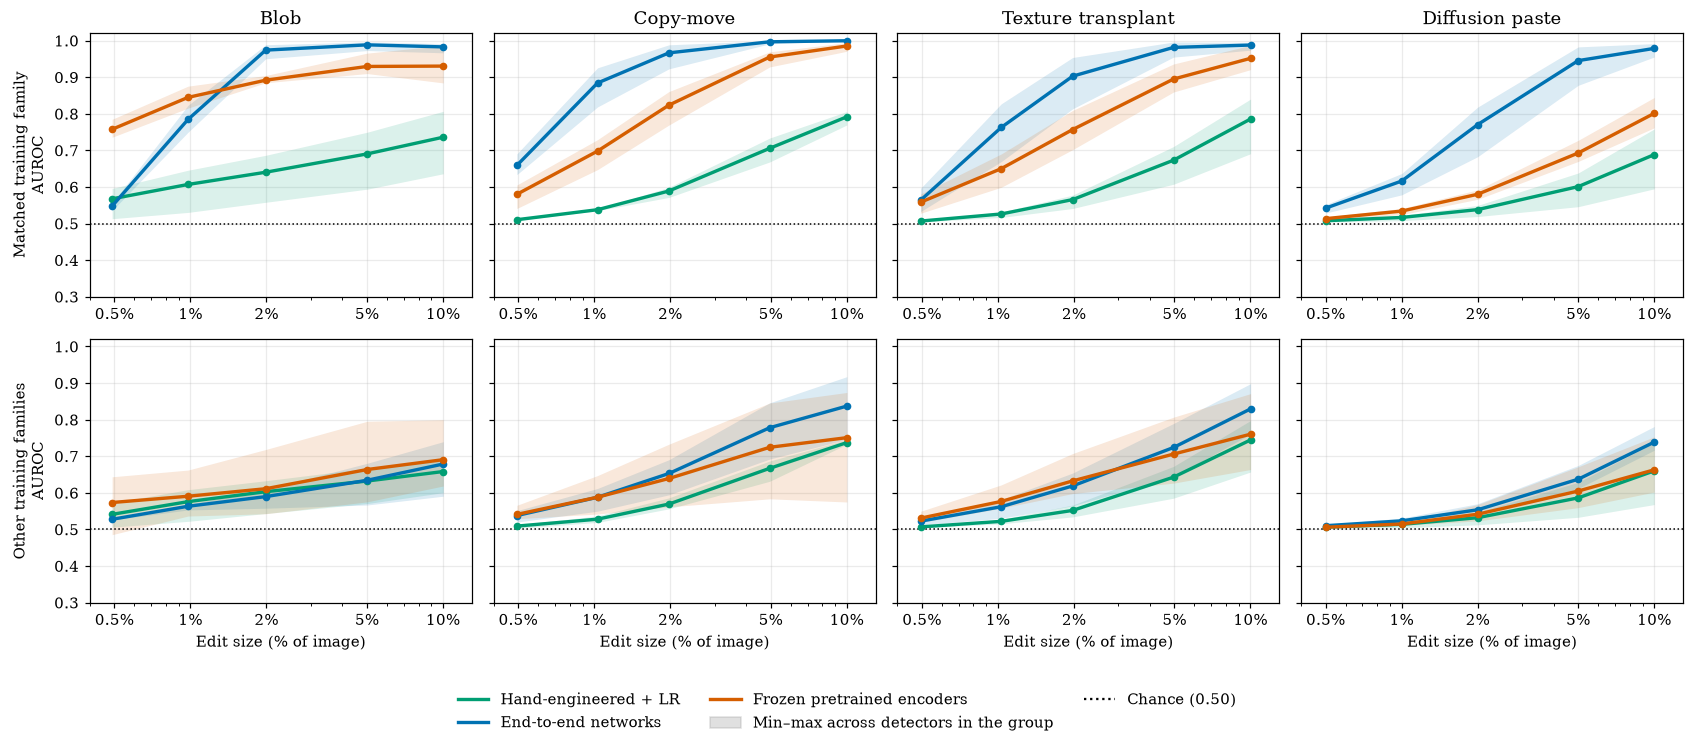

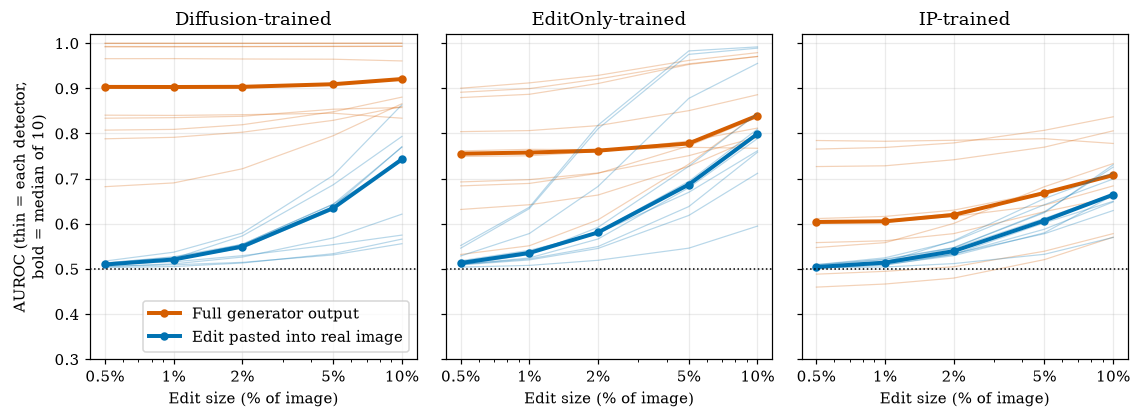

In [15]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import size_config as sc

plt.rcParams.update({"font.family":"serif","font.size":10,"axes.grid":True,"grid.alpha":.25,
                     "axes.axisbelow":True,"figure.dpi":110})
def save(fig, name):
    for ext in ("png","pdf"):
        fig.savefig(sc.FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")

NAME  = {"IP_Blob":"Blob","IP_CopyMove":"Copy-move","IP_TextureTransplant":"Texture transplant",
         "Diffusion_paste":"Diffusion paste","Diffusion_full":"Diffusion full"}
MATCH = {"IP_Blob":"IP-trained","IP_CopyMove":"IP-trained","IP_TextureTransplant":"IP-trained",
         "Diffusion_paste":"EditOnly-trained","Diffusion_full":"Diffusion-trained"}
OKI = {"orange":"#E69F00","sky":"#56B4E9","green":"#009E73","blue":"#0072B2","verm":"#D55E00"}
ECOL = {"IP_Blob":OKI["orange"],"IP_CopyMove":OKI["sky"],"IP_TextureTransplant":OKI["green"],
        "Diffusion_paste":OKI["blue"],"Diffusion_full":OKI["verm"]}
fmt_pct = mt.FuncFormatter(lambda v,_: f"{v:g}%")

R = R.dropna(subset=["auroc"]).copy()
R["matched"] = R.train == R.group.map(MATCH)
R["gain"] = R.auroc - 0.5                      # single Real set: the no-edit floor is 0.5

# ---------------- Figure 1: footprint vs cross-family transfer ----------------
def fig1(FP):
    Y = (R[~R.matched].groupby(["group","level"])
           .agg(y=("gain","mean"), y_lo=("gain",lambda s:s.quantile(.25)),
                y_hi=("gain",lambda s:s.quantile(.75)), area=("area","median")).reset_index())
    P = Y.merge(FP[["group","level","footprint"]], on=["group","level"], how="inner")
    if len(P) < len(Y): print("unmatched keys: check group/level names in FP")
    x, y = P.footprint.values, P.y.values
    b1, b0 = np.polyfit(x, y, 1); rng = np.random.default_rng(0)
    xs = np.linspace(x.min(), x.max(), 100)
    band = np.percentile([np.polyval(np.polyfit(x[i], y[i], 1), xs)
                          for i in (rng.integers(0,len(P),len(P)) for _ in range(2000))], [2.5,97.5], axis=0)
    r = np.corrcoef(x, y)[0,1]
    nf = P[P.group != "Diffusion_full"]; r_nf = np.corrcoef(nf.footprint, nf.y)[0,1]
    c1, c0 = np.polyfit(nf.footprint, nf.y, 1); xs2 = np.linspace(nf.footprint.min(), nf.footprint.max(), 50)
    pred, act, sst = [], [], 0.0                       # leave one edit type out
    for g in P.group.unique():
        tr, te = P[P.group != g], P[P.group == g]
        if len(tr) < 4: continue
        k1, k0 = np.polyfit(tr.footprint, tr.y, 1)
        pred += list(k0 + k1*te.footprint); act += list(te.y); sst += ((te.y - tr.y.mean())**2).sum()
    r2 = 1 - ((np.array(act)-np.array(pred))**2).sum()/sst
    print(f"r={r:.2f}; without full r={r_nf:.2f}; held-out R2={r2:.2f}; points={len(P)}")
    fig, ax = plt.subplots(figsize=(6.6,5))
    ax.fill_between(xs, band[0], band[1], color="#9e9e9e", alpha=.3, lw=0)
    l1, = ax.plot(xs, b0+b1*xs, "k", lw=1.5); l2, = ax.plot(xs2, c0+c1*xs2, "k--", lw=1.1)
    for g, d in P.groupby("group"):
        ax.errorbar(d.footprint, d.y, yerr=[d.y-d.y_lo, d.y_hi-d.y], fmt="none", ecolor=ECOL[g], alpha=.25, lw=1)
        ax.scatter(d.footprint, d.y, s=24+22*np.log2(100*d.area/0.5), color=ECOL[g], edgecolor="white", lw=.6, zorder=3)
    ax.axhline(0, color="grey", lw=.7, ls=":")
    ax.set_xlabel("Feature footprint (standardised mean shift vs real)")
    ax.set_ylabel("Cross-family gain over chance (AUROC − 0.5)")
    a = ax.legend([l1,l2,Line2D([],[],color="none")], [f"Linear fit (r = {r:.2f})",
                  f"Without Diffusion full (r = {r_nf:.2f})", f"Held-out edit type R² = {r2:.2f}"], loc="upper left")
    ax.add_artist(a)
    ax.legend([Line2D([],[],marker="o",ls="",color=ECOL[g]) for g in ECOL], [NAME[g] for g in ECOL],
              loc="lower right", title="Edit type (larger marker = larger edit)", title_fontsize=8)
    fig.tight_layout(); save(fig, "fig1_footprint_vs_transfer"); plt.show(); return P

# ---------------- Figure 2: detection vs size by detector group ----------------
GROUPS = {"Hand-engineered + LR":["spectral_lr","handcrafted_lr","lbp_lr"],
          "End-to-end networks":["cnn_densenet","supcon","npr"],
          "Frozen pretrained encoders":["clip_frozen","biomedclip_frozen","rad_dino","dinov2_frozen"]}
GCOL = dict(zip(GROUPS, [OKI["green"], OKI["blue"], OKI["verm"]]))
PAN = ["IP_Blob","IP_CopyMove","IP_TextureTransplant","Diffusion_paste"]

def fig2():
    fig, axes = plt.subplots(2, 4, figsize=(15.5,6.8), sharey=True)
    for j, g in enumerate(PAN):
        for i, row in enumerate(["Matched training family","Other training families"]):
            ax = axes[i,j]; E = R[R.group == g]; E = E[E.matched] if i == 0 else E[~E.matched]
            DL = E.groupby(["detector","level"]).agg(area=("area","median"), a=("auroc","mean")).reset_index()
            lv = DL.groupby("level").area.median().sort_values(); xx = 100*lv.values
            for gname, dets in GROUPS.items():
                piv = DL[DL.detector.isin(dets)].pivot(index="level", columns="detector", values="a").reindex(lv.index)
                c = GCOL[gname]
                ax.fill_between(xx, piv.min(axis=1), piv.max(axis=1), color=c, alpha=.14, lw=0)
                ax.plot(xx, piv.mean(axis=1), color=c, lw=2.2, marker="o", ms=4, zorder=3)
            ax.axhline(.5, color="black", ls=":", lw=1)
            ax.set_xscale("log"); ax.set_ylim(.3,1.02); ax.set_xlim(0.4, 13)
            ax.set_xticks([0.5,1,2,5,10]); ax.xaxis.set_major_formatter(fmt_pct)
            ax.xaxis.set_minor_formatter(mt.NullFormatter())
            if i == 0: ax.set_title(NAME[g])
            if j == 0: ax.set_ylabel(f"{row}\nAUROC")
            if i == 1: ax.set_xlabel("Edit size (% of image)")
    h = [Line2D([0],[0], color=c, lw=2.2, label=n) for n,c in GCOL.items()]
    h += [Patch(color="#999999", alpha=.3, label="Min–max across detectors in the group"),
          Line2D([0],[0], color="black", ls=":", label="Chance (0.50)")]
    fig.legend(handles=h, loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0,0.1,1,1)); save(fig, "fig2_detection_vs_size"); plt.show()

# ---------------- Figure 3: full output vs pasted edit ----------------
def fig3():
    D = R[R.group.isin(["Diffusion_full","Diffusion_paste"])]
    VC = {"Diffusion_full":OKI["verm"], "Diffusion_paste":OKI["blue"]}
    VN = {"Diffusion_full":"Full generator output", "Diffusion_paste":"Edit pasted into real image"}
    trs = ["Diffusion-trained","EditOnly-trained","IP-trained"]
    fig, axes = plt.subplots(1, 3, figsize=(10.5,3.9), sharey=True)
    for ax, tr in zip(axes, trs):
        for g, c in VC.items():
            S = D[(D.train == tr) & (D.group == g)]
            for det, d in S.groupby("detector"):
                d = d.sort_values("area"); ax.plot(100*d.area, d.auroc, color=c, lw=.8, alpha=.28)
            m = S.groupby("level").agg(area=("area","median"), med=("auroc","median")).sort_values("area")
            ax.plot(100*m.area, m.med, color=c, lw=2.6, marker="o", ms=4.5, label=VN[g])
        ax.axhline(.5, color="black", ls=":", lw=1); ax.set_xscale("log"); ax.set_ylim(.3,1.02)
        ax.set_xticks([0.5,1,2,5,10]); ax.xaxis.set_major_formatter(fmt_pct)
        ax.xaxis.set_minor_formatter(mt.NullFormatter()); ax.set_title(tr); ax.set_xlabel("Edit size (% of image)")
    axes[0].set_ylabel("AUROC (thin = each detector,\nbold = median of 10)"); axes[0].legend(loc="lower right")
    fig.tight_layout(); save(fig, "fig3_full_vs_paste"); plt.show()

fig2(); fig3()
# P = fig1(FP)    # FP: columns group, level, footprint  (from the Stage 3 footprint table)

r = 0.84; without Diffusion full r = 0.90; held-out R2 = 0.25; points = 25


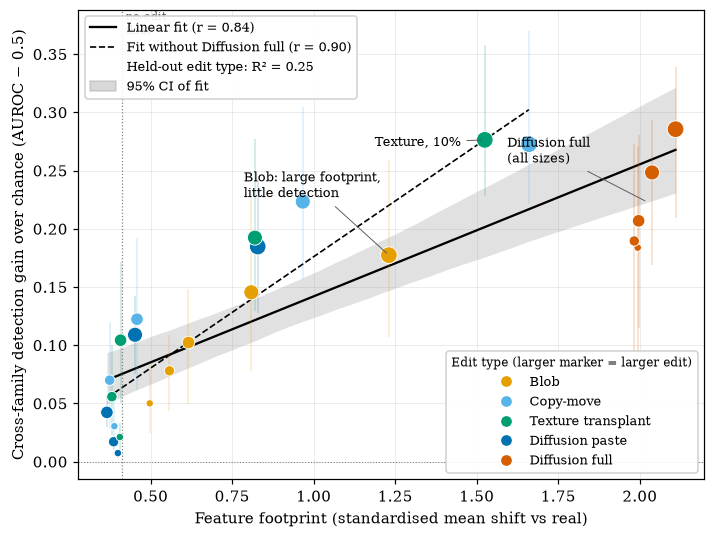

In [16]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.labelsize": 10, "legend.fontsize": 8.5, "axes.grid": True,
                     "grid.alpha": .25, "grid.linewidth": .6, "axes.axisbelow": True, "figure.dpi": 110})

NAME = {"IP_Blob": "Blob", "IP_CopyMove": "Copy-move", "IP_TextureTransplant": "Texture transplant",
        "Diffusion_paste": "Diffusion paste", "Diffusion_full": "Diffusion full"}
MATCH = {"IP_Blob": "IP-trained", "IP_CopyMove": "IP-trained", "IP_TextureTransplant": "IP-trained",
         "Diffusion_paste": "EditOnly-trained", "Diffusion_full": "Diffusion-trained"}
OKI = {"IP_Blob": "#E69F00", "IP_CopyMove": "#56B4E9", "IP_TextureTransplant": "#009E73",
       "Diffusion_paste": "#0072B2", "Diffusion_full": "#D55E00"}

# ---------- data ----------
FP = out["footprint"]                                   # group, level, footprint, ...
null_fp = out["footprint_report"]["null"]["footprint"]  # no-edit floor (set to None to hide)

D = R.dropna(subset=["auroc"]).copy()
D["gain"] = D.auroc - 0.5                               # single Real set: floor is 0.5
cross = D[D.train != D.group.map(MATCH)]                # transfer only: drop the matched family
Y = (cross.groupby(["group", "level"])
          .agg(y=("gain", "mean"), y_lo=("gain", lambda s: s.quantile(.25)),
               y_hi=("gain", lambda s: s.quantile(.75)), area=("area", "median")).reset_index())
P = Y.merge(FP[["group", "level", "footprint"]], on=["group", "level"], how="inner")
if len(P) < len(Y):
    miss = Y.merge(FP[["group", "level", "footprint"]], on=["group", "level"], how="left", indicator=True)
    print("unmatched keys (check naming):", miss.query("_merge=='left_only'")[["group", "level"]].values.tolist())

# ---------- fits ----------
x, y = P.footprint.values, P.y.values
b1, b0 = np.polyfit(x, y, 1)
rng = np.random.default_rng(0)
xs = np.linspace(x.min(), x.max(), 100)
band = np.percentile([np.polyval(np.polyfit(x[i], y[i], 1), xs)
                      for i in (rng.integers(0, len(P), len(P)) for _ in range(2000))], [2.5, 97.5], axis=0)
r = np.corrcoef(x, y)[0, 1]
nf = P[P.group != "Diffusion_full"]
r_nf = np.corrcoef(nf.footprint, nf.y)[0, 1]
c1, c0 = np.polyfit(nf.footprint, nf.y, 1)
xs2 = np.linspace(nf.footprint.min(), nf.footprint.max(), 50)
pred, act, sst = [], [], 0.0                            # leave one edit type out
for g in P.group.unique():
    tr, te = P[P.group != g], P[P.group == g]
    if len(tr) < 4: continue
    k1, k0 = np.polyfit(tr.footprint, tr.y, 1)
    pred += list(k0 + k1 * te.footprint); act += list(te.y); sst += ((te.y - tr.y.mean()) ** 2).sum()
r2 = 1 - ((np.array(act) - np.array(pred)) ** 2).sum() / sst
print(f"r = {r:.2f}; without Diffusion full r = {r_nf:.2f}; held-out R2 = {r2:.2f}; points = {len(P)}")

# ---------- figure ----------
fig, ax = plt.subplots(figsize=(6.6, 5.0))
ax.fill_between(xs, band[0], band[1], color="#9e9e9e", alpha=.30, lw=0)
ln1, = ax.plot(xs, b0 + b1 * xs, color="black", lw=1.5)
ln2, = ax.plot(xs2, c0 + c1 * xs2, color="black", lw=1.1, ls="--")
for g, d in P.groupby("group"):
    ax.errorbar(d.footprint, d.y, yerr=[(d.y - d.y_lo).clip(lower=0), (d.y_hi - d.y).clip(lower=0)],
                fmt="none", ecolor=OKI[g], alpha=.22, lw=1, zorder=2)
    ax.scatter(d.footprint, d.y, s=24 + 22 * np.log2(100 * d.area / 0.5), color=OKI[g],
               edgecolor="white", lw=.6, zorder=3)
if null_fp is not None:
    ax.axvline(null_fp, color="grey", lw=.8, ls=":")
    ax.text(null_fp, ax.get_ylim()[1], " no-edit\n floor", va="top", ha="left", fontsize=7.5, color="#555")

def note(sel, text, dx, dy):
    if len(sel):
        q = sel.iloc[0]
        ax.annotate(text, (q.footprint, q.y), xytext=(dx, dy), textcoords="offset points", fontsize=8.5,
                    arrowprops=dict(arrowstyle="-", lw=.6, color="#555"))
big = lambda g: P[P.group == g].sort_values("area", ascending=False)
note(big("IP_TextureTransplant"), "Texture, 10%", -72, -4)
note(big("IP_Blob"), "Blob: large footprint,\nlittle detection", -95, 38)
fz = P[P.group == "Diffusion_full"]
if len(fz):
    ax.annotate("Diffusion full\n(all sizes)", (fz.footprint.mean(), fz.y.mean()), xytext=(-92, 26),
                textcoords="offset points", fontsize=8.5, arrowprops=dict(arrowstyle="-", lw=.6, color="#555"))
ax.axhline(0, color="grey", lw=.7, ls=":")
ax.set_xlabel("Feature footprint (standardised mean shift vs real)")
ax.set_ylabel("Cross-family detection gain over chance (AUROC − 0.5)")
leg1 = ax.legend([ln1, ln2, Line2D([], [], color="none"), Patch(color="#9e9e9e", alpha=.4)],
                 [f"Linear fit (r = {r:.2f})", f"Fit without Diffusion full (r = {r_nf:.2f})",
                  f"Held-out edit type: R² = {r2:.2f}", "95% CI of fit"],
                 loc="upper left", frameon=True, framealpha=.9)
ax.add_artist(leg1)
ax.legend([Line2D([], [], marker="o", ls="", color=OKI[g]) for g in OKI], [NAME[g] for g in OKI],
          loc="lower right", title="Edit type (larger marker = larger edit)", title_fontsize=8,
          frameon=True, framealpha=.9)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(sc.FIG_DIR / f"fig1_footprint_vs_transfer.{ext}", dpi=300, bbox_inches="tight")
P.to_csv(sc.FIG_DIR / "fig1_points.csv", index=False)
plt.show()

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.labelsize": 10, "legend.fontsize": 8.5, "axes.grid": True,
                     "grid.alpha": .25, "grid.linewidth": .6, "axes.axisbelow": True, "figure.dpi": 110,
                     "pdf.fonttype": 42})                                   # CHANGED: embed fonts

NAME = {"IP_Blob": "Blob", "IP_CopyMove": "Copy-move", "IP_TextureTransplant": "Texture transplant",
        "Diffusion_paste": "Diffusion paste", "Diffusion_full": "Diffusion full"}
MATCH = {"IP_Blob": "IP-trained", "IP_CopyMove": "IP-trained", "IP_TextureTransplant": "IP-trained",
         "Diffusion_paste": "EditOnly-trained", "Diffusion_full": "Diffusion-trained"}
OKI = {"IP_Blob": "#E69F00", "IP_CopyMove": "#56B4E9", "IP_TextureTransplant": "#009E73",
       "Diffusion_paste": "#0072B2", "Diffusion_full": "#D55E00"}

# ---------- data ----------
FP = out["footprint"]
null_info = out["footprint_report"]["null"]                                 # CHANGED: keep lo/hi for the band
null_fp, null_lo, null_hi = null_info["footprint"], null_info.get("lo"), null_info.get("hi")

D = R.dropna(subset=["auroc"]).copy()
D["gain"] = D.auroc - 0.5
cross = D[D.train != D.group.map(MATCH)]
Y = (cross.groupby(["group", "level"])
          .agg(y=("gain", "mean"), y_lo=("gain", lambda s: s.quantile(.25)),
               y_hi=("gain", lambda s: s.quantile(.75)), area=("area", "median")).reset_index())
P = Y.merge(FP[["group", "level", "footprint"]], on=["group", "level"], how="inner")
if len(P) < len(Y):
    miss = Y.merge(FP[["group", "level", "footprint"]], on=["group", "level"], how="left", indicator=True)
    print("unmatched keys (check naming):", miss.query("_merge=='left_only'")[["group", "level"]].values.tolist())

# ---------- fits ----------
x, y = P.footprint.values, P.y.values
b1, b0 = np.polyfit(x, y, 1)
rng = np.random.default_rng(0)
xs = np.linspace(x.min(), x.max(), 100)
band = np.percentile([np.polyval(np.polyfit(x[i], y[i], 1), xs)
                      for i in (rng.integers(0, len(P), len(P)) for _ in range(2000))], [2.5, 97.5], axis=0)
r = np.corrcoef(x, y)[0, 1]
nf = P[P.group != "Diffusion_full"]
r_nf = np.corrcoef(nf.footprint, nf.y)[0, 1]
c1, c0 = np.polyfit(nf.footprint, nf.y, 1)
xs2 = np.linspace(nf.footprint.min(), nf.footprint.max(), 50)
pred, act, sst = [], [], 0.0
for g in P.group.unique():
    tr, te = P[P.group != g], P[P.group == g]
    if len(tr) < 4: continue
    k1, k0 = np.polyfit(tr.footprint, tr.y, 1)
    pred += list(k0 + k1 * te.footprint); act += list(te.y); sst += ((te.y - tr.y.mean()) ** 2).sum()
r2 = 1 - ((np.array(act) - np.array(pred)) ** 2).sum() / sst
print(f"r = {r:.2f}; without Diffusion full r = {r_nf:.2f}; held-out R2 = {r2:.2f}; points = {len(P)}")

# ---------- figure ----------
fig, ax = plt.subplots(figsize=(6.6, 5.0))
if null_lo is not None and null_hi is not None:                            # CHANGED: no-edit band instead of text label
    ax.axvspan(null_lo, null_hi, color="#bdbdbd", alpha=.18, lw=0, zorder=0)
ax.axvline(null_fp, color="grey", lw=.8, ls=":")
ax.fill_between(xs, band[0], band[1], color="#9e9e9e", alpha=.30, lw=0)
ln1, = ax.plot(xs, b0 + b1 * xs, color="black", lw=1.5)
ln2, = ax.plot(xs2, c0 + c1 * xs2, color="black", lw=1.1, ls="--")
for g, d in P.groupby("group"):
    ax.errorbar(d.footprint, d.y, yerr=[(d.y - d.y_lo).clip(lower=0), (d.y_hi - d.y).clip(lower=0)],
                fmt="none", ecolor=OKI[g], alpha=.22, lw=1, zorder=2)
    ax.scatter(d.footprint, d.y, s=24 + 22 * np.log2(100 * d.area / 0.5), color=OKI[g],
               edgecolor="white", lw=.6, zorder=3)

def note(sel, text, dx, dy):
    if len(sel):
        q = sel.iloc[0]
        ax.annotate(text, (q.footprint, q.y), xytext=(dx, dy), textcoords="offset points", fontsize=8.5,
                    arrowprops=dict(arrowstyle="-", lw=.6, color="#555"))
big = lambda g: P[P.group == g].sort_values("area", ascending=False)
note(big("IP_TextureTransplant"), "Texture, 10%", -72, -4)
note(big("IP_Blob"), "Blob: large footprint,\nlittle detection", -95, 38)
fz = P[P.group == "Diffusion_full"]
if len(fz):                                                                 # CHANGED: label in a clear area (data coords)
    ax.annotate("Diffusion full\n(all sizes)", (fz.footprint.mean(), fz.y.mean()),
                xytext=(1.50, 0.125), textcoords="data", ha="center", fontsize=8.5,
                arrowprops=dict(arrowstyle="-", lw=.6, color="#555"))
ax.axhline(0, color="grey", lw=.7, ls=":")
ax.set_xlim(0.3, 2.25)
ax.set_xlabel("Feature footprint (standardised mean shift vs real)")
ax.set_ylabel("Cross-family detection gain over chance (AUROC − 0.5)")
band_lbl = (f"No-edit footprint ({null_fp:.2f}; band {null_lo:.2f}–{null_hi:.2f})"
            if null_lo is not None else f"No-edit footprint ({null_fp:.2f})")
leg1 = ax.legend([ln1, ln2, Line2D([], [], color="none"), Patch(color="#9e9e9e", alpha=.4),
                  Line2D([], [], color="grey", ls=":")],
                 [f"Linear fit (r = {r:.2f})", f"Fit without Diffusion full (r = {r_nf:.2f})",
                  f"Held-out edit type: R² = {r2:.2f}", "95% CI of fit", band_lbl],
                 loc="upper left", frameon=True, framealpha=.9)
ax.add_artist(leg1)
ax.legend([Line2D([], [], marker="o", ls="", color=OKI[g]) for g in OKI], [NAME[g] for g in OKI],
          loc="lower right", title="Edit type (larger marker = larger edit)", title_fontsize=8,
          frameon=True, framealpha=.9)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(sc.FIG_DIR / f"fig1_footprint_vs_transfer.{ext}", dpi=300, bbox_inches="tight")
P.to_csv(sc.FIG_DIR / "fig1_points.csv", index=False)
plt.show()

In [17]:
import numpy as np, pandas as pd

def _cross(a, y, thr):
    """Smallest area where the curve first reaches thr, interpolated in log(area)."""
    ok = y >= thr
    if not ok.any():
        return np.nan, "not reached"
    i = int(np.argmax(ok))
    if i == 0:
        return float(a[0]), "at/below smallest size"
    x0, x1, y0, y1 = np.log(a[i-1]), np.log(a[i]), y[i-1], y[i]
    return float(np.exp(x0 + (thr - y0) * (x1 - x0) / (y1 - y0))), "interpolated"

def min_detectable(R, thr=0.70, exclude=("Diffusion_full",)):
    """Per (train, detector, group): usable size (measured) and crossing size (interpolated),
    both under the point rule and the stricter rule (lower bound >= thr)."""
    rows = []
    for (tr, det, g), d in R[~R.group.isin(exclude)].groupby(["train", "detector", "group"]):
        d = d.sort_values("area")
        a, y = d.area.to_numpy(float), d.auroc.to_numpy()
        lo = d.auroc_lo.to_numpy()
        pt = (y >= thr) & (lo > 0.5)          # your rule
        st = lo >= thr                         # strict: confidently >= thr
        cx, note = _cross(a, y, thr)
        rows.append(dict(train=tr, detector=det, group=g,
                         usable=a[pt].min() if pt.any() else np.nan,
                         usable_strict=a[st].min() if st.any() else np.nan,
                         crossing=cx, crossing_note=note))
    return pd.DataFrame(rows)

U = min_detectable(R)

# minimum over detectors = "smallest size ANY detector can detect"
best = (U.sort_values("usable")
          .groupby(["train", "group"])
          .first()                              # row of the best detector
          .reset_index()[["train", "group", "detector", "usable", "usable_strict", "crossing", "crossing_note"]])
print((best.assign(**{c: (best[c]*100).round(2) for c in ["usable", "usable_strict", "crossing"]})).to_string(index=False))

            train                group       detector  usable  usable_strict  crossing          crossing_note
Diffusion-trained      Diffusion_paste         supcon    5.00          10.00      4.75           interpolated
Diffusion-trained              IP_Blob       rad_dino    5.01           5.01      2.37           interpolated
Diffusion-trained          IP_CopyMove       rad_dino    1.98           4.96      1.69           interpolated
Diffusion-trained IP_TextureTransplant       rad_dino    1.98           4.96      1.96           interpolated
 EditOnly-trained      Diffusion_paste         supcon    2.00           2.00      1.27           interpolated
 EditOnly-trained              IP_Blob       rad_dino    1.99           1.99      1.06           interpolated
 EditOnly-trained          IP_CopyMove         supcon    1.98           1.98      1.34           interpolated
 EditOnly-trained IP_TextureTransplant       rad_dino    1.98           4.96      1.79           interpolated
       IP-

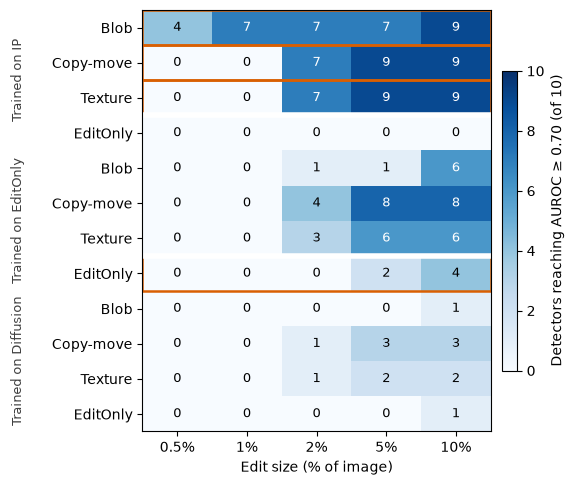

In [37]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd, config
FIG_DIR = config.DET_RESULTS_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
t = pd.read_csv(config.DET_RESULTS_DIR / "smallest_detectable_size_70.csv", index_col=[0, 1])
SER   = [("IP_Blob","Blob"),("IP_CopyMove","Copy-move"),("IP_TextureTransplant","Texture"),("Diffusion_paste","EditOnly")]
TRAIN = [("IP","IP"),("Diffusion_EditOnly","EditOnly"),("Diffusion","Diffusion")]
MATCH = {("IP","IP_Blob"),("IP","IP_CopyMove"),("IP","IP_TextureTransplant"),("Diffusion_EditOnly","Diffusion_paste")}
AREAS = [0.005, 0.01, 0.02, 0.05, 0.10]
rows, lab, matched = [], [], []
for tk, tn in TRAIN:
    for sk, sn in SER:
        s = t.xs(tk, level="train_family")[sk]
        rows.append([(s <= a + 1e-9).sum() for a in AREAS])
        lab.append(sn); matched.append((tk, sk) in MATCH)
H = np.array(rows)
fig, ax = plt.subplots(figsize=(6.2, 5.0))
im = ax.imshow(H, cmap="Blues", vmin=0, vmax=10, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, int(H[i,j]), ha="center", va="center", color="white" if H[i,j] >= 6 else "black", fontsize=9)
    if matched[i]:
        ax.add_patch(Rectangle((-0.5, i-0.5), H.shape[1], 1, fill=False, ec="#d95f02", lw=1.8))
ax.set_xticks(range(5)); ax.set_xticklabels(["0.5%","1%","2%","5%","10%"])
ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab)
for k in (3, 7): ax.axhline(k-0.5, color="white", lw=4)
for k, (_, tn) in enumerate(TRAIN):
    ax.text(-0.36, 4*k+1.5, f"Trained on {tn}", rotation=90, ha="center", va="center",
            transform=ax.get_yaxis_transform(), fontsize=9, color="0.25")
ax.set_xlabel("Edit size (% of image)")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03, label="Detectors reaching AUROC ≥ 0.70 (of 10)")
fig.tight_layout(); fig.savefig(FIG_DIR/"ladder_detectors_by_size.pdf", bbox_inches="tight"); plt.show()

r=0.84; without full r=0.90; held-out R2=0.25; points=25


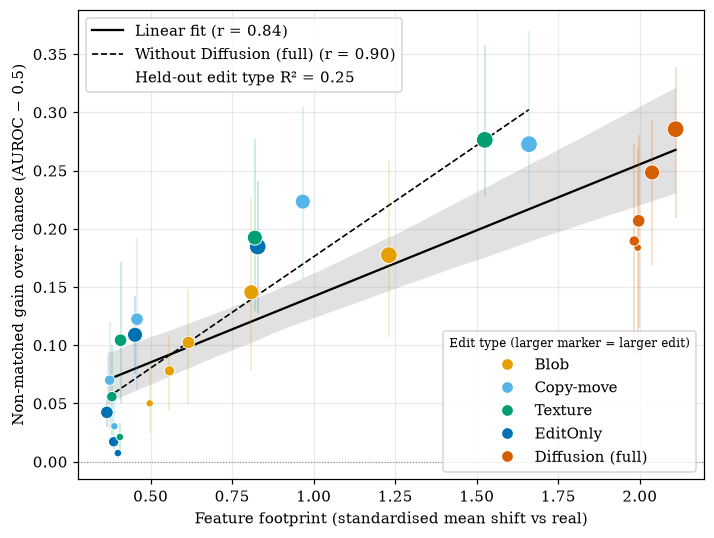

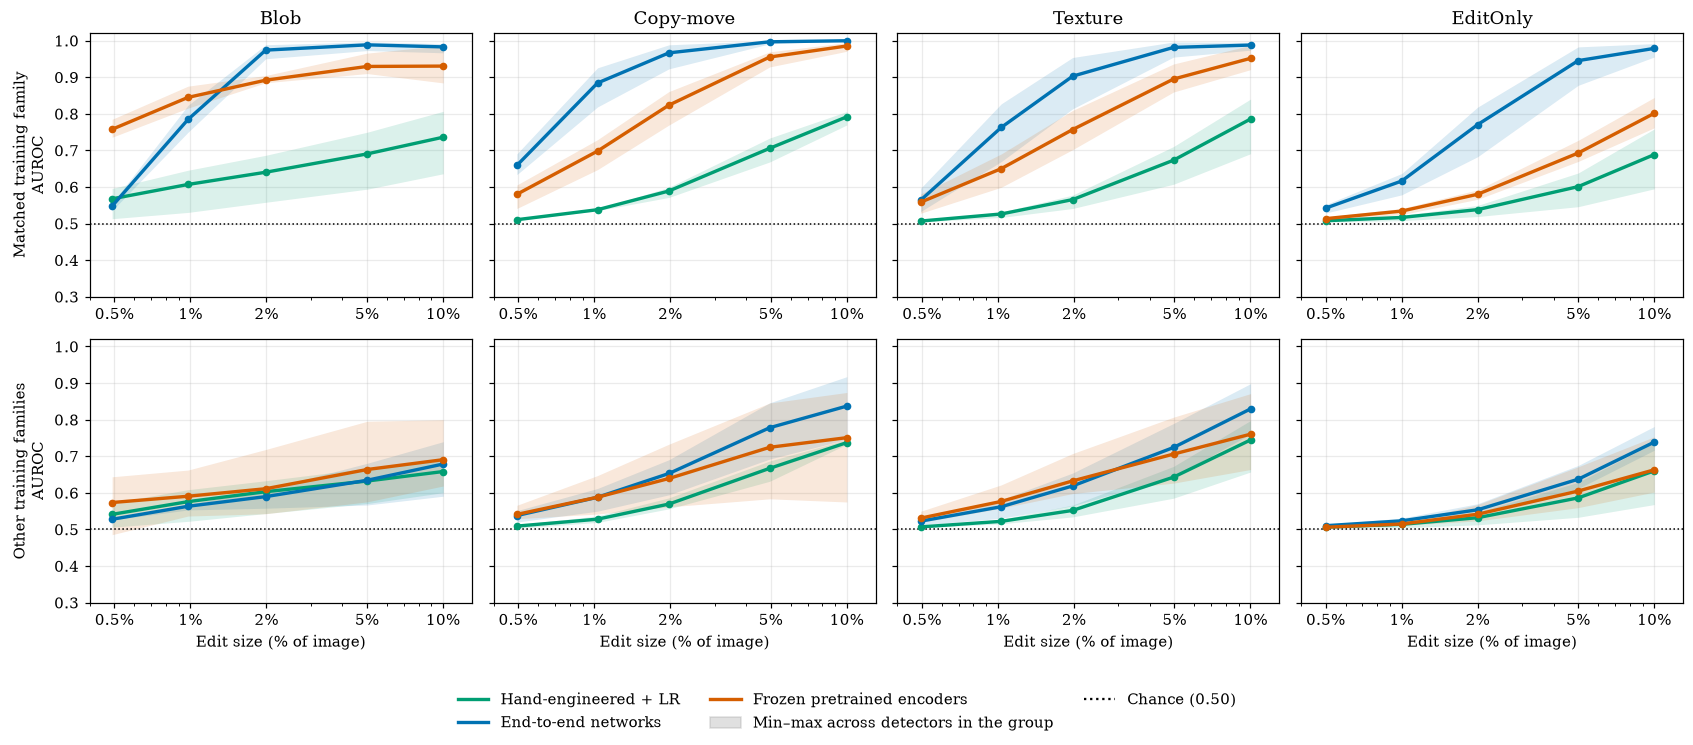

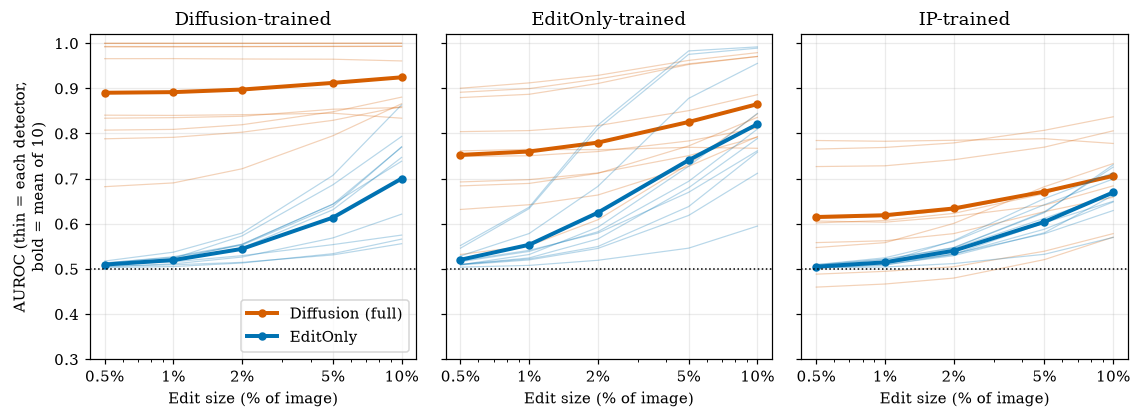

In [38]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import config, size_config as sc
import stage3_forensics.ladder_frequency as lf

# ---- data: ladder scores and footprint table ----
R = pd.read_csv("/data/aa8624/thesis_2500/data/detection/results/ladder_scoring/ladder_results.csv")
feat = lf.ef.load_feature_table(lf.FEAT_CSV)
FP = lf.footprint_report(feat)["ladder"]          # columns include group, level, footprint

plt.rcParams.update({"font.family":"serif","font.size":10,"axes.grid":True,"grid.alpha":.25,
                     "axes.axisbelow":True,"figure.dpi":110})
def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(sc.FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")

NAME = {"IP_Blob":"Blob","IP_CopyMove":"Copy-move","IP_TextureTransplant":"Texture",
        "Diffusion_paste":"EditOnly","Diffusion_full":"Diffusion (full)"}
MATCH = {"IP_Blob":"IP-trained","IP_CopyMove":"IP-trained","IP_TextureTransplant":"IP-trained",
         "Diffusion_paste":"EditOnly-trained","Diffusion_full":"Diffusion-trained"}
OKI = {"orange":"#E69F00","sky":"#56B4E9","green":"#009E73","blue":"#0072B2","verm":"#D55E00"}
ECOL = {"IP_Blob":OKI["orange"],"IP_CopyMove":OKI["sky"],"IP_TextureTransplant":OKI["green"],
        "Diffusion_paste":OKI["blue"],"Diffusion_full":OKI["verm"]}
fmt_pct = mt.FuncFormatter(lambda v, _: f"{v:g}%")

R = R.dropna(subset=["auroc"]).copy()
R["matched"] = R.train == R.group.map(MATCH)
R["gain"] = R.auroc - 0.5

# ---------------- Figure 1: footprint vs non-matched gain ----------------
def fig1(FP):
    Y = (R[~R.matched].groupby(["group","level"])
         .agg(y=("gain","mean"), y_lo=("gain", lambda s: s.quantile(.25)),
              y_hi=("gain", lambda s: s.quantile(.75)), area=("area","median")).reset_index())
    P = Y.merge(FP[["group","level","footprint"]], on=["group","level"], how="inner")
    if len(P) < len(Y): print("unmatched keys: check group/level names in FP")
    x, y = P.footprint.values, P.y.values
    b1, b0 = np.polyfit(x, y, 1); rng = np.random.default_rng(0)
    xs = np.linspace(x.min(), x.max(), 100)
    band = np.percentile([np.polyval(np.polyfit(x[i], y[i], 1), xs)
                          for i in (rng.integers(0, len(P), len(P)) for _ in range(2000))], [2.5, 97.5], axis=0)
    r = np.corrcoef(x, y)[0, 1]
    nf = P[P.group != "Diffusion_full"]; r_nf = np.corrcoef(nf.footprint, nf.y)[0, 1]
    c1, c0 = np.polyfit(nf.footprint, nf.y, 1); xs2 = np.linspace(nf.footprint.min(), nf.footprint.max(), 50)
    pred, act, sst = [], [], 0.0
    for g in P.group.unique():
        tr, te = P[P.group != g], P[P.group == g]
        if len(tr) < 4: continue
        k1, k0 = np.polyfit(tr.footprint, tr.y, 1)
        pred += list(k0 + k1*te.footprint); act += list(te.y); sst += ((te.y - tr.y.mean())**2).sum()
    r2 = 1 - ((np.array(act) - np.array(pred))**2).sum() / sst
    print(f"r={r:.2f}; without full r={r_nf:.2f}; held-out R2={r2:.2f}; points={len(P)}")
    fig, ax = plt.subplots(figsize=(6.6, 5))
    ax.fill_between(xs, band[0], band[1], color="#9e9e9e", alpha=.3, lw=0)
    l1, = ax.plot(xs, b0 + b1*xs, "k", lw=1.5); l2, = ax.plot(xs2, c0 + c1*xs2, "k--", lw=1.1)
    for g, d in P.groupby("group"):
        ax.errorbar(d.footprint, d.y, yerr=[d.y - d.y_lo, d.y_hi - d.y], fmt="none", ecolor=ECOL[g], alpha=.25, lw=1)
        ax.scatter(d.footprint, d.y, s=24 + 22*np.log2(100*d.area/0.5), color=ECOL[g], edgecolor="white", lw=.6, zorder=3)
    ax.axhline(0, color="grey", lw=.7, ls=":")
    ax.set_xlabel("Feature footprint (standardised mean shift vs real)")
    ax.set_ylabel("Non-matched gain over chance (AUROC − 0.5)")
    a = ax.legend([l1, l2, Line2D([], [], color="none")],
                  [f"Linear fit (r = {r:.2f})", f"Without Diffusion (full) (r = {r_nf:.2f})",
                   f"Held-out edit type R² = {r2:.2f}"], loc="upper left")
    ax.add_artist(a)
    ax.legend([Line2D([], [], marker="o", ls="", color=ECOL[g]) for g in ECOL], [NAME[g] for g in ECOL],
              loc="lower right", title="Edit type (larger marker = larger edit)", title_fontsize=8)
    fig.tight_layout(); save(fig, "fig1_footprint_vs_transfer"); plt.show(); return P

# ---------------- Figure 2: detection vs size by detector group ----------------
GROUPS = {"Hand-engineered + LR":["spectral_lr","handcrafted_lr","lbp_lr"],
          "End-to-end networks":["cnn_densenet","supcon","npr"],
          "Frozen pretrained encoders":["clip_frozen","biomedclip_frozen","rad_dino","dinov2_frozen"]}
GCOL = dict(zip(GROUPS, [OKI["green"], OKI["blue"], OKI["verm"]]))
PAN = ["IP_Blob","IP_CopyMove","IP_TextureTransplant","Diffusion_paste"]
def fig2():
    fig, axes = plt.subplots(2, 4, figsize=(15.5, 6.8), sharey=True)
    for j, g in enumerate(PAN):
        for i, row in enumerate(["Matched training family", "Other training families"]):
            ax = axes[i, j]; E = R[R.group == g]; E = E[E.matched] if i == 0 else E[~E.matched]
            DL = E.groupby(["detector","level"]).agg(area=("area","median"), a=("auroc","mean")).reset_index()
            lv = DL.groupby("level").area.median().sort_values(); xx = 100*lv.values
            for gname, dets in GROUPS.items():
                piv = DL[DL.detector.isin(dets)].pivot(index="level", columns="detector", values="a").reindex(lv.index)
                c = GCOL[gname]
                ax.fill_between(xx, piv.min(axis=1), piv.max(axis=1), color=c, alpha=.14, lw=0)
                ax.plot(xx, piv.mean(axis=1), color=c, lw=2.2, marker="o", ms=4, zorder=3)
            ax.axhline(.5, color="black", ls=":", lw=1)
            ax.set_xscale("log"); ax.set_ylim(.3, 1.02); ax.set_xlim(0.4, 13)
            ax.set_xticks([0.5, 1, 2, 5, 10]); ax.xaxis.set_major_formatter(fmt_pct)
            ax.xaxis.set_minor_formatter(mt.NullFormatter())
            if i == 0: ax.set_title(NAME[g])
            if j == 0: ax.set_ylabel(f"{row}\nAUROC")
            if i == 1: ax.set_xlabel("Edit size (% of image)")
    h = [Line2D([0], [0], color=c, lw=2.2, label=n) for n, c in GCOL.items()]
    h += [Patch(color="#999999", alpha=.3, label="Min–max across detectors in the group"),
          Line2D([0], [0], color="black", ls=":", label="Chance (0.50)")]
    fig.legend(handles=h, loc="lower center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0.1, 1, 1)); save(fig, "fig2_detection_vs_size"); plt.show()

# ---------------- Figure 3: Diffusion (full) vs EditOnly ----------------
def fig3():
    D = R[R.group.isin(["Diffusion_full","Diffusion_paste"])]
    VC = {"Diffusion_full":OKI["verm"], "Diffusion_paste":OKI["blue"]}
    VN = {"Diffusion_full":"Diffusion (full)", "Diffusion_paste":"EditOnly"}
    trs = ["Diffusion-trained","EditOnly-trained","IP-trained"]
    fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.9), sharey=True)
    for ax, tr in zip(axes, trs):
        for g, c in VC.items():
            S = D[(D.train == tr) & (D.group == g)]
            for det, d in S.groupby("detector"):
                d = d.sort_values("area"); ax.plot(100*d.area, d.auroc, color=c, lw=.8, alpha=.28)
            m = S.groupby("level").agg(area=("area","median"), mean=("auroc","mean")).sort_values("area")
            ax.plot(100*m.area, m["mean"], color=c, lw=2.6, marker="o", ms=4.5, label=VN[g])
        ax.axhline(.5, color="black", ls=":", lw=1); ax.set_xscale("log"); ax.set_ylim(.3, 1.02)
        ax.set_xticks([0.5, 1, 2, 5, 10]); ax.xaxis.set_major_formatter(fmt_pct)
        ax.xaxis.set_minor_formatter(mt.NullFormatter()); ax.set_title(tr); ax.set_xlabel("Edit size (% of image)")
    axes[0].set_ylabel("AUROC (thin = each detector,\nbold = mean of 10)"); axes[0].legend(loc="lower right")
    fig.tight_layout(); save(fig, "fig3_full_vs_paste"); plt.show()

P = fig1(FP); fig2(); fig3()

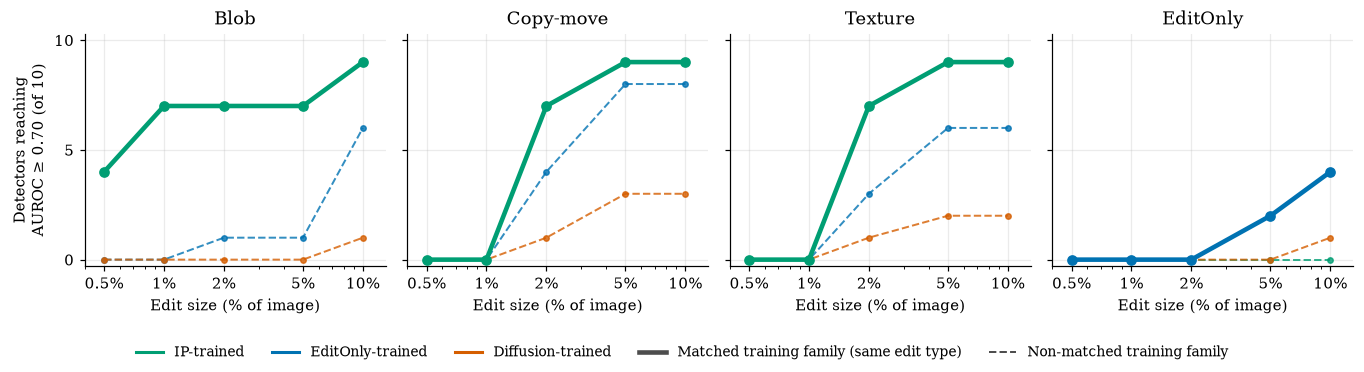

In [41]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mt
from matplotlib.lines import Line2D
import config
FIG_DIR = config.DET_RESULTS_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)
t = pd.read_csv(config.DET_RESULTS_DIR / "smallest_detectable_size_70.csv", index_col=[0, 1])
SER   = [("IP_Blob","Blob"),("IP_CopyMove","Copy-move"),("IP_TextureTransplant","Texture"),("Diffusion_paste","EditOnly")]
TRAIN = [("IP","IP-trained","#009E73"),("Diffusion_EditOnly","EditOnly-trained","#0072B2"),("Diffusion","Diffusion-trained","#D55E00")]
MATCH = {("IP","IP_Blob"),("IP","IP_CopyMove"),("IP","IP_TextureTransplant"),("Diffusion_EditOnly","Diffusion_paste")}
AREAS = [0.005, 0.01, 0.02, 0.05, 0.10]
X = [100*a for a in AREAS]
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.4), sharey=True)
for ax, (sk, sn) in zip(axes, SER):
    for tk, tn, col in TRAIN:
        s = t.xs(tk, level="train_family")[sk]
        y = [(s <= a + 1e-9).sum() for a in AREAS]
        if (tk, sk) in MATCH:
            ax.plot(X, y, color=col, lw=3, marker="o", ms=6, zorder=3)
        else:
            ax.plot(X, y, color=col, lw=1.3, ls="--", marker="o", ms=3.5, alpha=.8, zorder=2)
    ax.set_xscale("log"); ax.set_xticks(X); ax.set_xlim(0.4, 13)
    ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}%"))
    ax.xaxis.set_minor_formatter(mt.NullFormatter())
    ax.set_ylim(-0.3, 10.3); ax.set_yticks([0, 5, 10])
    ax.set_title(sn); ax.set_xlabel("Edit size (% of image)")
    ax.grid(alpha=.25); ax.spines[["top","right"]].set_visible(False)
axes[0].set_ylabel("Detectors reaching\nAUROC ≥ 0.70 (of 10)")
h  = [Line2D([0],[0], color=c, lw=2, label=n) for _, n, c in TRAIN]
h += [Line2D([0],[0], color="0.3", lw=3, label="Matched training family (same edit type)"),
      Line2D([0],[0], color="0.3", lw=1.3, ls="--", label="Non-matched training family")]
fig.legend(handles=h, loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig(FIG_DIR/"ladder_detectors_by_size.pdf", bbox_inches="tight"); plt.show()

## Supplementary

### How much of edit mask lies outside the region

### Diffusion

In [9]:
import numpy as np
from PIL import Image
import config

def outside_fraction(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    if m.sum() == 0:
        return np.nan
    o = (size - crop) // 2
    return 1 - m[o:o + crop, o:o + crop].sum() / m.sum()

files = sorted(config.DIFFUSION_EDIT_MASK_ROOT.glob("*_edit_mask.png"))
out = np.array([outside_fraction(f, 224) for f in files])
print(len(files), "masks; any part outside 224 crop:", np.mean(out > 0).round(3), "| max:", np.nanmax(out).round(3))

2491 masks; any part outside 224 crop: 0.03 | max: 0.372


In [14]:
import numpy as np
from PIL import Image
import config

def counts(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    o = (size - crop) // 2
    inside = m[o:o + crop, o:o + crop].sum()
    return m.sum(), m.sum() - inside

files = sorted(config.DIFFUSION_EDIT_MASK_ROOT.glob("*_edit_mask.png"))
tot, out = np.sum([counts(f, 224) for f in files], axis=0)
print(f"edited pixels outside the 224 crop: {out / tot:.4f} of all edited pixels")

edited pixels outside the 224 crop: 0.0018 of all edited pixels


In [17]:
import re
import numpy as np, pandas as pd
from PIL import Image
from pathlib import Path
import config

ladder = Path(config.SYNTHETIC_DIR) / "Diffusion_size_ladder"

# 1) what mask files are in each size folder?
levels = sorted([d for d in ladder.iterdir() if d.is_dir() and re.fullmatch(r"d\d+(p\d+)?", d.name)],
                key=lambda d: float(d.name[1:].replace("p", ".")))
for d in levels:
    ms = [f for f in d.rglob("*.png") if "mask" in f.name.lower() and "lung" not in f.name.lower()]
    print(f"{d.name:6s} {len(ms):5d} mask files   e.g. {ms[0].relative_to(ladder) if ms else '-'}")

d0p5     499 mask files   e.g. d0p5/masks/cab7bd95-1e76f5d7-eba32616-1e1e9b95-1f131be0_edit_mask.png
d1       497 mask files   e.g. d1/masks/6c22ebdf-e5f48411-67c09fd6-fb456360-1b66edd3_edit_mask.png
d2       496 mask files   e.g. d2/masks/5b99c23b-5c51d0c1-b1d359c9-b2f5a2e2-190c5052_edit_mask.png
d5       496 mask files   e.g. d5/masks/4576cd84-9271f0b7-0002ba90-e006c11d-8caa00ff_edit_mask.png
d10      490 mask files   e.g. d10/masks/0bae5adc-aa6665ec-0cdb021b-e17e0bbe-9067d1e1_edit_mask.png


In [18]:
def counts(path, crop=224, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    o = (size - crop) // 2
    inside = m[o:o + crop, o:o + crop].sum()
    return m.sum(), m.sum() - inside

rows = []
for d in levels:
    fs = [f for f in d.rglob("*.png") if "mask" in f.name.lower() and "lung" not in f.name.lower()]
    c = np.array([counts(f) for f in fs])
    tot, out = c[:, 0], c[:, 1]
    frac = np.where(tot > 0, out / np.maximum(tot, 1), np.nan)
    rows.append(dict(level=d.name, n=len(fs),
                     masks_with_any_outside=round(float(np.mean(out > 0)), 3),
                     pixels_outside=round(float(out.sum() / tot.sum()), 4),
                     max_out=round(float(np.nanmax(frac)), 3)))
print(pd.DataFrame(rows).to_string(index=False))

level   n  masks_with_any_outside  pixels_outside  max_out
 d0p5 499                   0.002          0.0019    0.973
   d1 497                   0.004          0.0016    0.780
   d2 496                   0.010          0.0016    0.587
   d5 496                   0.024          0.0022    0.372
  d10 490                   0.078          0.0031    0.305


### IP

In [10]:
import numpy as np, pandas as pd
from PIL import Image
from pathlib import Path
import config

def outside_fraction(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    if m.sum() == 0:
        return np.nan
    o = (size - crop) // 2
    return 1 - m[o:o + crop, o:o + crop].sum() / m.sum()

files = sorted(Path(config.SYNTHETIC_DIR).glob("IP*/**/metadata/*_metadata.csv"))
print(len(files), "metadata files found")           # check this first
rows = []
for f in files:
    d = pd.read_csv(f)
    col = next((c for c in ("mask_path", "edit_mask") if c in d.columns), None)
    if col is None:
        print("no mask column in", f); continue
    paths = d[col].dropna()
    out = np.array([outside_fraction(p, 224) for p in paths])
    rows.append(dict(file=str(f.relative_to(config.SYNTHETIC_DIR)), n=len(out),
                     any_outside=round(float(np.mean(out > 0)), 3),
                     mean_out=round(float(np.nanmean(out)), 3), max_out=round(float(np.nanmax(out)), 3)))
print(pd.DataFrame(rows).to_string(index=False))

6 metadata files found
                                                         file    n  any_outside  mean_out  max_out
                 IP/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
IP_size_ladder/a0p5/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
  IP_size_ladder/a1/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
 IP_size_ladder/a10/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
  IP_size_ladder/a2/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
  IP_size_ladder/a5/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0


In [16]:
import numpy as np, pandas as pd
from PIL import Image
from pathlib import Path
import config

def outside_fraction(path, crop, size=256):
    m = np.asarray(Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)) > 127
    if m.sum() == 0:
        return np.nan
    o = (size - crop) // 2
    return 1 - m[o:o + crop, o:o + crop].sum() / m.sum()

def mask_column(columns):
    for name in ("mask_path", "edit_mask"):
        if name in columns:
            return name
    return next((c for c in columns if "mask" in c.lower() and c.lower().endswith(("path", "file"))), None)

root = Path(config.SYNTHETIC_DIR)
files = sorted(f for base in ("IP", "IP_size_ladder") for f in (root / base).rglob("*.csv")
               if "metadata" in f.name and "error" not in f.name.lower() and f.stat().st_size > 0)
print(len(files), "non-empty metadata files")

rows = []
for f in files:
    try:
        cols = pd.read_csv(f, nrows=1).columns
    except pd.errors.EmptyDataError:
        print("empty:", f.relative_to(root)); continue
    col = mask_column(cols)
    if col is None:
        print("no mask path column:", f.relative_to(root)); continue
    paths = [p for p in pd.read_csv(f)[col].dropna().astype(str) if Path(p).exists()]
    if not paths:
        print("no existing mask files:", f.relative_to(root)); continue
    out = np.array([outside_fraction(p, 224) for p in paths])
    rows.append(dict(file=str(f.relative_to(root)), n=len(out),
                     any_outside=round(float(np.mean(out > 0)), 3),
                     mean_out=round(float(np.nanmean(out)), 3),
                     max_out=round(float(np.nanmax(out)), 3)))
print(pd.DataFrame(rows).to_string(index=False))

18 non-empty metadata files
                                                                     file    n  any_outside  mean_out  max_out
                             IP/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
                             IP/copy/reports/copy_move_final_metadata.csv 2500          0.0       0.0      0.0
                 IP/texture/reports/texture_transplant_final_metadata.csv 2500          0.0       0.0      0.0
            IP_size_ladder/a0p5/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
            IP_size_ladder/a0p5/copy/reports/copy_move_final_metadata.csv 2500          0.0       0.0      0.0
IP_size_ladder/a0p5/texture/reports/texture_transplant_final_metadata.csv 2500          0.0       0.0      0.0
              IP_size_ladder/a1/blob/metadata/blob_synthetic_metadata.csv 2500          0.0       0.0      0.0
              IP_size_ladder/a1/copy/reports/copy_move_final_metadata.csv 2500      

#### Diffusion and masks

In [6]:
import numpy as np, pandas as pd, config
from pathlib import Path
from PIL import Image

root = Path(config.SYNTHETIC_DIR) / "Diffusion_size_ladder"
levels = ["d0p5", "d1", "d2", "d5", "d10"]
prod = Path(config.DIFFUSION_EDIT_MASK_ROOT)
ld = lambda p: np.asarray(Image.open(p).convert("L")) > 127

ids = sorted(p.name.replace("_edit_mask.png", "") for p in (root / "d5" / "masks").glob("*_edit_mask.png"))
rows = []
for d in ids:
    ms = {lv: ld(root / lv / "masks" / f"{d}_edit_mask.png") for lv in levels
          if (root / lv / "masks" / f"{d}_edit_mask.png").exists()}
    r = {"dicom": d}
    for a, b in zip(levels[:-1], levels[1:]):
        if a in ms and b in ms:
            r[f"{a}_inside_{b}"] = (ms[a] & ms[b]).sum() / ms[a].sum()
    pp = prod / f"{d}_edit_mask.png"
    if "d5" in ms and pp.exists():
        pm = ld(pp)
        if pm.shape == ms["d5"].shape:
            r["d5_vs_production_IoU"] = (pm & ms["d5"]).sum() / (pm | ms["d5"]).sum()
    rows.append(r)
print(pd.DataFrame(rows).describe().loc[["count", "mean", "min"]].round(3).to_string())

       d0p5_inside_d1  d1_inside_d2  d2_inside_d5  d5_inside_d10  d5_vs_production_IoU
count           496.0         496.0         496.0          490.0                 496.0
mean              1.0           1.0           1.0            1.0                   1.0
min               1.0           1.0           1.0            1.0                   1.0


#### Diffusion paste baseline

In [8]:
import numpy as np, pandas as pd, config

R = pd.read_csv("/data/aa8624/thesis_2500/data/detection/results/ladder_scoring/ladder_results.csv")
print(R.shape, sorted(R.group.unique()))      # expect 750 rows; check the exact name of the full-diffusion series

B = pd.read_csv(config.DET_RESULTS_CSV)
recon = (B[(B.role == "test_cross") & (B.test_family == "Diffusion_Reconstruction")]
         .groupby(["train_family", "model"]).auroc.mean().rename("recon_auroc"))

F = R[R.group == "Diffusion_full"].copy()
F["train_family"] = F["slug"].str.split("__to__").str[0]
F = F.merge(recon, left_on=["train_family", "detector"], right_index=True, how="left")

ok_half  = (F.auroc >= 0.70) & (F.auroc_lo > 0.5)
ok_recon = (F.auroc >= 0.70) & (F.auroc_lo > F.recon_auroc)
F["area_half"], F["area_recon"] = F.area.where(ok_half), F.area.where(ok_recon)

S = F.groupby(["train_family", "detector"]).agg(
        recon_auroc=("recon_auroc", "first"),
        smallest_vs_0p5=("area_half", "min"),
        smallest_vs_recon=("area_recon", "min")).round(3)
print(S.to_string())

(750, 16) ['Diffusion_full', 'Diffusion_paste', 'IP_Blob', 'IP_CopyMove', 'IP_TextureTransplant']
                                      recon_auroc  smallest_vs_0p5  smallest_vs_recon
train_family       detector                                                          
Diffusion          biomedclip_frozen        0.742            0.005              0.005
                   clip_frozen              0.731            0.005              0.005
                   cnn_densenet             0.889            0.005              0.005
                   dinov2_frozen            0.649            0.005              0.005
                   handcrafted_lr           0.758            0.005              0.005
                   lbp_lr                   0.756            0.005              0.005
                   npr                      0.941            0.005              0.005
                   rad_dino                 0.566            0.020              0.020
                   spectral_lr            

In [9]:
import numpy as np, pandas as pd, config

R = pd.read_csv("/data/aa8624/thesis_2500/data/detection/results/ladder_scoring/ladder_results.csv")
B = pd.read_csv(config.DET_RESULTS_CSV)
recon = (B[(B.role == "test_cross") & (B.test_family == "Diffusion_Reconstruction")]
         .groupby(["train_family", "model"]).auroc.mean().rename("recon_auroc"))

R = R.copy()
R["train_family"] = R["slug"].str.split("__to__").str[0]
R = R.merge(recon, left_on=["train_family", "detector"], right_index=True, how="left")
R["baseline"] = np.where(R.group == "Diffusion_full", R.recon_auroc, 0.5)

def smallest(thr):
    ok = (R.auroc >= thr) & (R.auroc_lo > R.baseline)
    s = (R.assign(area=R.area.where(ok))
           .groupby(["train_family", "detector", "group"]).area.min().unstack("group"))
    return s

tables = {thr: smallest(thr) for thr in (0.70, 0.80, 0.90)}
for thr, t in tables.items():
    t.to_csv(config.DET_RESULTS_DIR / f"smallest_detectable_size_{int(thr*100)}.csv")
    print(f"\nsmallest detectable area (fraction of image), AUROC >= {thr}  (NaN = not reached within 10%)")
    print(t.round(3).to_string())


smallest detectable area (fraction of image), AUROC >= 0.7  (NaN = not reached within 10%)
group                                 Diffusion_full  Diffusion_paste  IP_Blob  IP_CopyMove  IP_TextureTransplant
train_family       detector                                                                                      
Diffusion          biomedclip_frozen           0.005             0.10      NaN         0.05                  0.10
                   clip_frozen                 0.005              NaN      NaN          NaN                   NaN
                   cnn_densenet                0.005             0.10      NaN         0.10                  0.10
                   dinov2_frozen               0.005              NaN      NaN          NaN                   NaN
                   handcrafted_lr              0.005              NaN      NaN         0.10                  0.10
                   lbp_lr                      0.005              NaN      NaN         0.10                   